# Лабораторная работа 3. Кластеризация

**Дисциплина:** Системы искусственного интеллекта и машинное обучение
**Выполнил:** Герасимов С. П., гр. АВТ-313
**Датасет:** Wine Dataset (UCI Machine Learning Repository) — химический состав 178 образцов итальянских вин

## 1. Введение

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**
1. Провести дескриптивный анализ датасета: размерность, типы признаков, пропуски, распределения (близость к нормальному), информационная значимость признаков, выбросы; проверить условия применимости кластеризации.
2. Выполнить стандартизацию признаков и обосновать выбор метода масштабирования; по матрице диаграмм рассеивания оценить структуру данных и предположительное число кластеров.
3. Обосновать выбор двух методов кластеризации и реализовать их: **K-means** и **иерархическая агломеративная кластеризация (Ward)**; подобрать число кластеров методом локтя и силуэтным анализом, построить дендрограмму.
4. Рассчитать внутренние (Silhouette, Calinski–Harabasz, Davies–Bouldin, Dunn, компактность, межкластерные расстояния) и внешние (Rand, ARI, Jaccard, Fowlkes–Mallows, NMI/AMI, V-measure) метрики и интерпретировать их.
5. Исследовать влияние параметров: числа кластеров k и инициализации для K-means, способа связи и метрики для иерархического метода, а также ε и min_samples для DBSCAN (дополнительно).
6. Визуализировать кластеры в пространстве главных компонент, интерпретировать центры кластеров в исходных единицах и сравнить методы.

## 2. Описание датасета

Wine Dataset — результат химического анализа вин, выращенных в одном регионе Италии из трёх разных сортов винограда (Forina et al., UCI ML Repository). Файл `wine.csv` содержит 178 строк и 14 столбцов:

| Признак | Описание | Единицы |
|---|---|---|
| `alcohol` | содержание алкоголя | % об. |
| `malic_acid` | яблочная кислота | г/л |
| `ash` | зола | г/л |
| `alcalinity_of_ash` | щёлочность золы | мэкв/л |
| `magnesium` | магний | мг/л |
| `total_phenols` | общие фенолы | г/л |
| `flavanoids` | флавоноиды | г/л |
| `nonflavanoid_phenols` | нефлавоноидные фенолы | г/л |
| `proanthocyanins` | проантоцианидины | г/л |
| `color_intensity` | интенсивность цвета | у. е. |
| `hue` | оттенок | у. е. |
| `od280_od315` | отношение оптических плотностей OD280/OD315 (содержание белков) | — |
| `proline` | пролин (аминокислота) | мг/л |
| `class` | сорт винограда (1, 2, 3) — **только для внешней проверки** | — |

Все 13 признаков — непрерывные числовые. Столбец `class` в кластеризации не участвует: он отделяется от матрицы признаков сразу после загрузки и используется только для расчёта внешних метрик и справочных таблиц.

In [1]:
from pathlib import Path
from itertools import combinations
from math import comb
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.stats import skew, kurtosis, shapiro
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, cdist, squareform
from scipy.optimize import linear_sum_assignment

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score, adjusted_mutual_info_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score, fowlkes_mallows_score,
)

SEED = 42
FIG_DIR = Path("figures")
RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

In [2]:
df = pd.read_csv("wine.csv")

TARGET = "class"
FEATURES = [c for c in df.columns if c != TARGET]
CLASS_NAMES = {1: "Сорт 1", 2: "Сорт 2", 3: "Сорт 3"}

X = df[FEATURES].copy()
y_true = df[TARGET].astype(int).to_numpy()

print("Размерность:", df.shape)
print("Объектов:", df.shape[0], "| признаков для кластеризации:", len(FEATURES))
display(df.head())
display(pd.DataFrame({"Тип": df.dtypes.astype(str), "Пропусков": df.isna().sum(), "Уникальных": df.nunique()}).T)
print("Полных дубликатов строк:", df.duplicated().sum())
print("Распределение исходных классов (в кластеризации не участвуют):")
display(df[TARGET].value_counts().sort_index().rename("Объектов").to_frame().T)

Размерность: (178, 14)
Объектов: 178 | признаков для кластеризации: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,1


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,class
Тип,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
Пропусков,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Уникальных,126,133,79,63,53,97,132,39,101,132,78,122,121,3


Полных дубликатов строк: 0
Распределение исходных классов (в кластеризации не участвуют):


class,1,2,3
Объектов,59,71,48


Датасет содержит **178 объектов и 14 столбцов**: 13 признаков типа `float64` и метка `class` типа `int64`. Пропусков нет ни в одном столбце, полных дубликатов нет, поэтому заполнение пропусков не требуется. Классы почти сбалансированы: 59 / 71 / 48 объектов. В кластеризацию передаётся только `X = df[FEATURES]`, а метки хранятся отдельно в `y_true`.

### 2.1. Описательные статистики

In [3]:
desc = X.describe().T
desc["median"] = X.median()
desc["cv"] = X.std() / X.mean()
desc["skew"] = X.apply(skew)
desc["kurtosis"] = X.apply(kurtosis)
desc["shapiro_p"] = [shapiro(X[c]).pvalue for c in FEATURES]
desc = desc[["mean", "median", "std", "min", "25%", "75%", "max", "cv", "skew", "kurtosis", "shapiro_p"]]
display(desc.round(3))

,mean,median,std,min,25%,75%,max,cv,skew,kurtosis,shapiro_p
alcohol,13.001,13.050,0.812,11.03,12.362,13.678,14.83,0.062,-0.051,-0.862,0.020
malic_acid,2.336,1.865,1.117,0.74,1.602,3.082,5.80,0.478,1.031,0.257,0.000
ash,2.367,2.360,0.274,1.36,2.210,2.558,3.23,0.116,-0.175,1.079,0.039
alcalinity_of_ash,19.495,19.500,3.340,10.60,17.200,21.500,30.00,0.171,0.211,0.441,0.264
magnesium,99.742,98.000,14.282,70.00,88.000,107.000,162.00,0.143,1.089,2.013,0.000
total_phenols,2.295,2.355,0.626,0.98,1.742,2.800,3.88,0.273,0.086,-0.846,0.004
flavanoids,2.029,2.135,0.999,0.34,1.205,2.875,5.08,0.492,0.025,-0.889,0.000
nonflavanoid_phenols,0.362,0.340,0.124,0.13,0.270,0.438,0.66,0.344,0.446,-0.653,0.000
proanthocyanins,1.591,1.555,0.572,0.41,1.250,1.950,3.58,0.360,0.513,0.506,0.014
color_intensity,5.058,4.690,2.318,1.28,3.220,6.200,13.00,0.458,0.861,0.337,0.000


- **Шкалы признаков различаются на 3–4 порядка**: `proline` имеет среднее 746.9 и σ = 314.9, `magnesium` — 99.7 и 14.3, а `nonflavanoid_phenols` — 0.36 и 0.12, `hue` — 0.96 и 0.23. Без масштабирования евклидово расстояние определялось бы почти только пролином.
- **Относительный разброс (CV)** наибольший у `flavanoids` (0.49), `malic_acid` (0.48), `color_intensity` (0.46), `proline` (0.42) — эти признаки сильнее всего варьируют между образцами; наименьший — у `alcohol` (0.06) и `ash` (0.12).
- **Асимметрия**: заметный правый хвост у `magnesium` (1.09), `malic_acid` (1.03), `color_intensity` (0.86), `proline` (0.76) — у них среднее больше медианы (например, `proline`: 746.9 против 673.5). Остальные признаки почти симметричны (|skew| < 0.52).
- **Эксцесс**: у `magnesium` 2.01 (тяжёлые хвосты, есть отдельные очень большие значения), у `flavanoids`, `total_phenols`, `od280_od315`, `alcohol` отрицательный (−0.85…−1.09) — распределения «плосковерхие», что типично для смеси нескольких групп.
- **Тест Шапиро–Уилка** на уровне 0.05 не отвергает нормальность только для `alcalinity_of_ash` (p = 0.264); для остальных 12 признаков p < 0.05.

### 2.2. Распределения признаков (гистограммы)

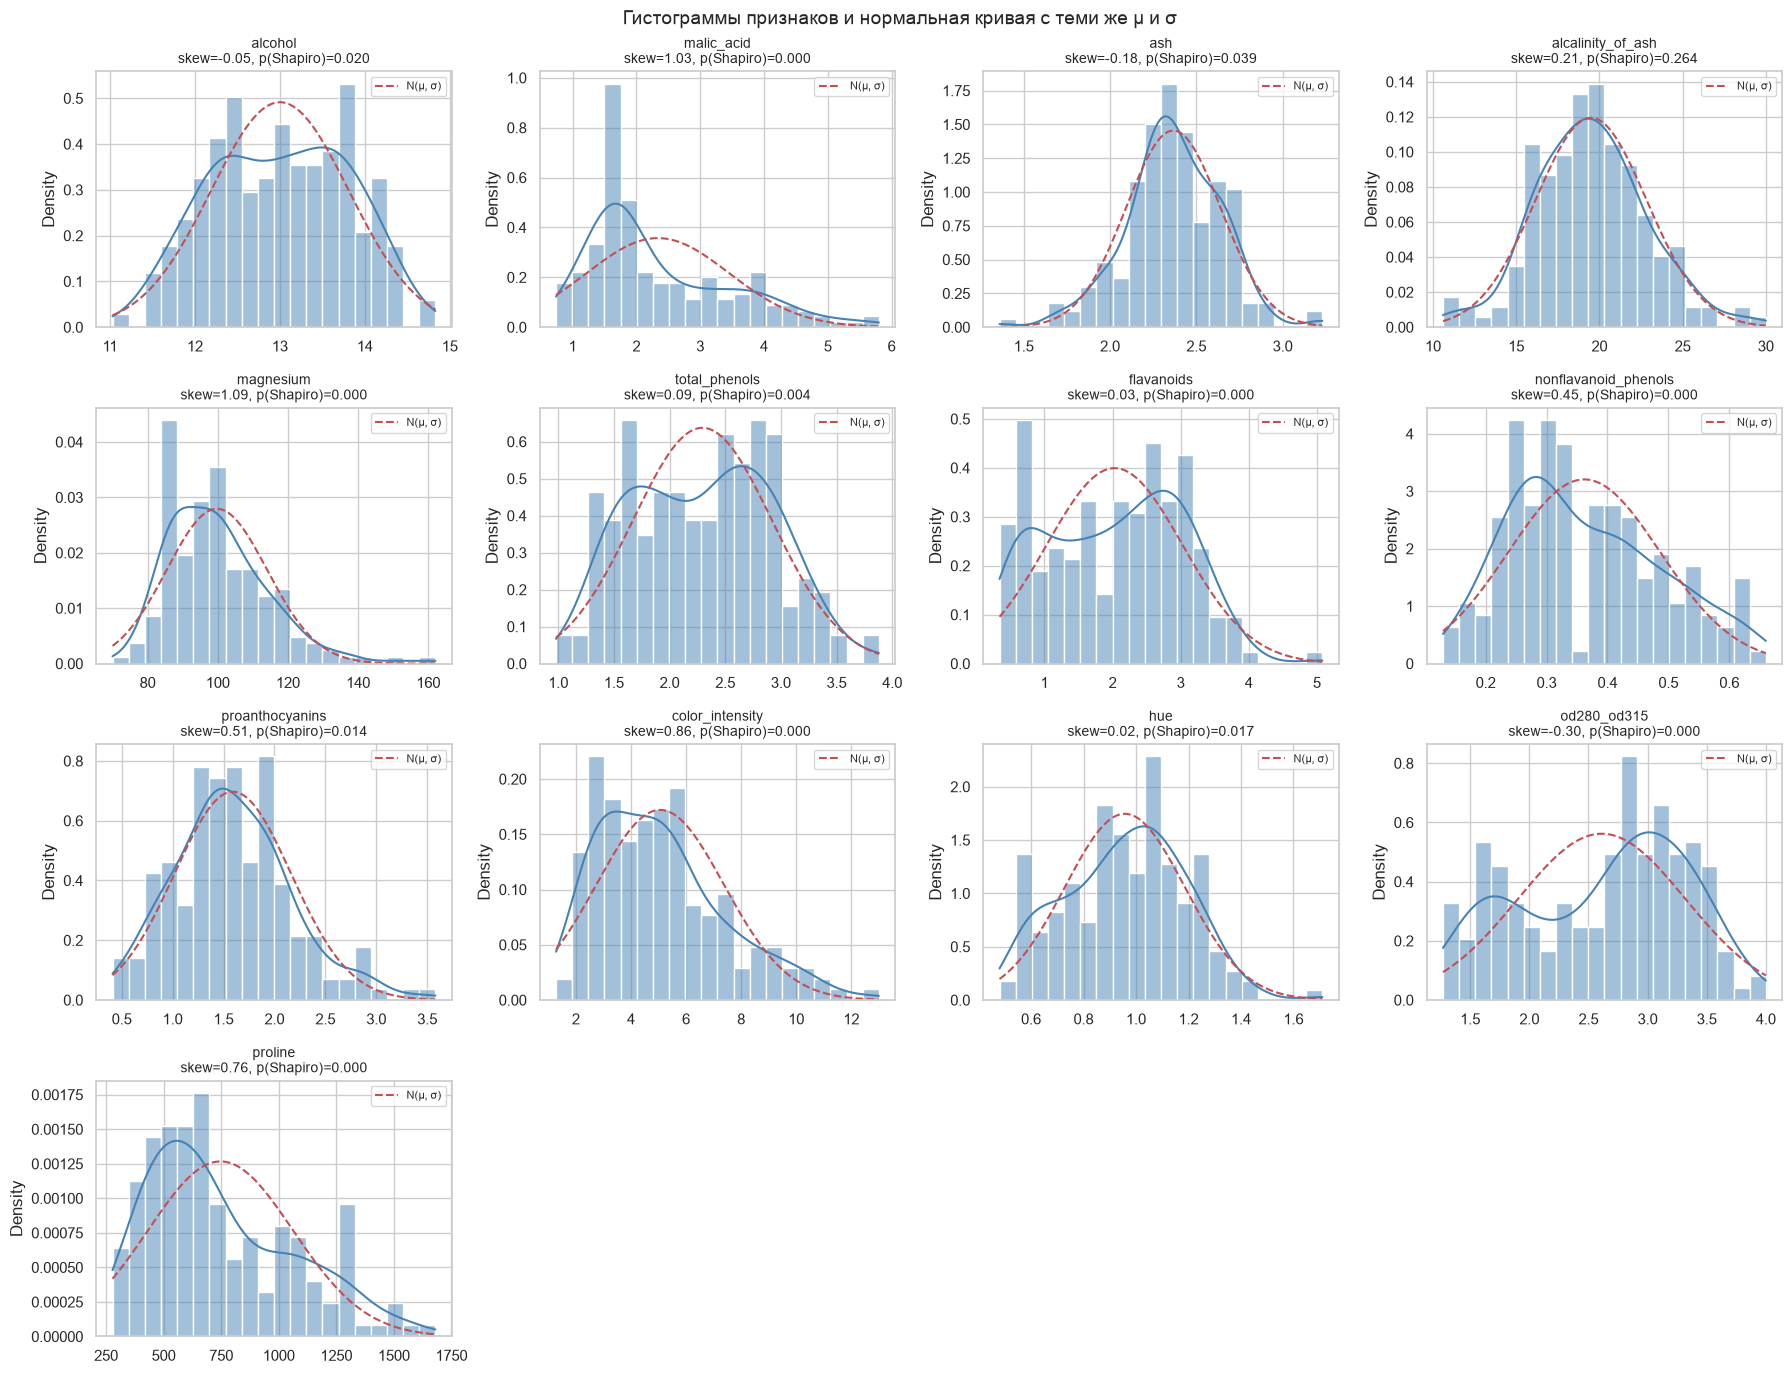

In [4]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.ravel()
for ax, col in zip(axes, FEATURES):
    sns.histplot(X[col], bins=20, kde=True, stat="density", ax=ax, color="steelblue")
    xs = np.linspace(X[col].min(), X[col].max(), 200)
    m, s = X[col].mean(), X[col].std()
    ax.plot(xs, np.exp(-(xs - m) ** 2 / (2 * s ** 2)) / (s * np.sqrt(2 * np.pi)), "r--", lw=1.5, label="N(μ, σ)")
    ax.set_title(f"{col}\nskew={skew(X[col]):.2f}, p(Shapiro)={shapiro(X[col]).pvalue:.3f}", fontsize=10)
    ax.set_xlabel("")
    ax.legend(fontsize=8)
for ax in axes[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Гистограммы признаков и нормальная кривая с теми же μ и σ", fontsize=14)
plt.tight_layout()
savefig("histograms")
plt.show()

Близость к нормальному распределению оценивалась визуально (сравнение гистограммы и KDE с наложенной кривой N(μ, σ)) и по коэффициентам асимметрии и эксцесса:

- **Близки к нормальному**: `alcalinity_of_ash`, `ash`, `hue`, `alcohol` — колоколообразная форма, асимметрия около нуля; у `alcohol` вершина уплощена.
- **Скошены вправо**: `malic_acid`, `magnesium`, `color_intensity`, `proline`, `proanthocyanins` — длинный правый хвост, мода левее среднего.
- **Многовершинные (би-/тримодальные)**: `flavanoids`, `total_phenols`, `od280_od315`, `proline`, `alcohol` — на гистограммах видны две-три вершины. Это прямой признак того, что выборка является смесью нескольких групп с разными средними, то есть косвенно подтверждает наличие кластерной структуры.

Для K-means и иерархического метода Ward нормальность признаков не требуется; асимметрия и выбросы учитываются при выборе масштабирования (раздел 3).

### 2.3. Информационная значимость признаков

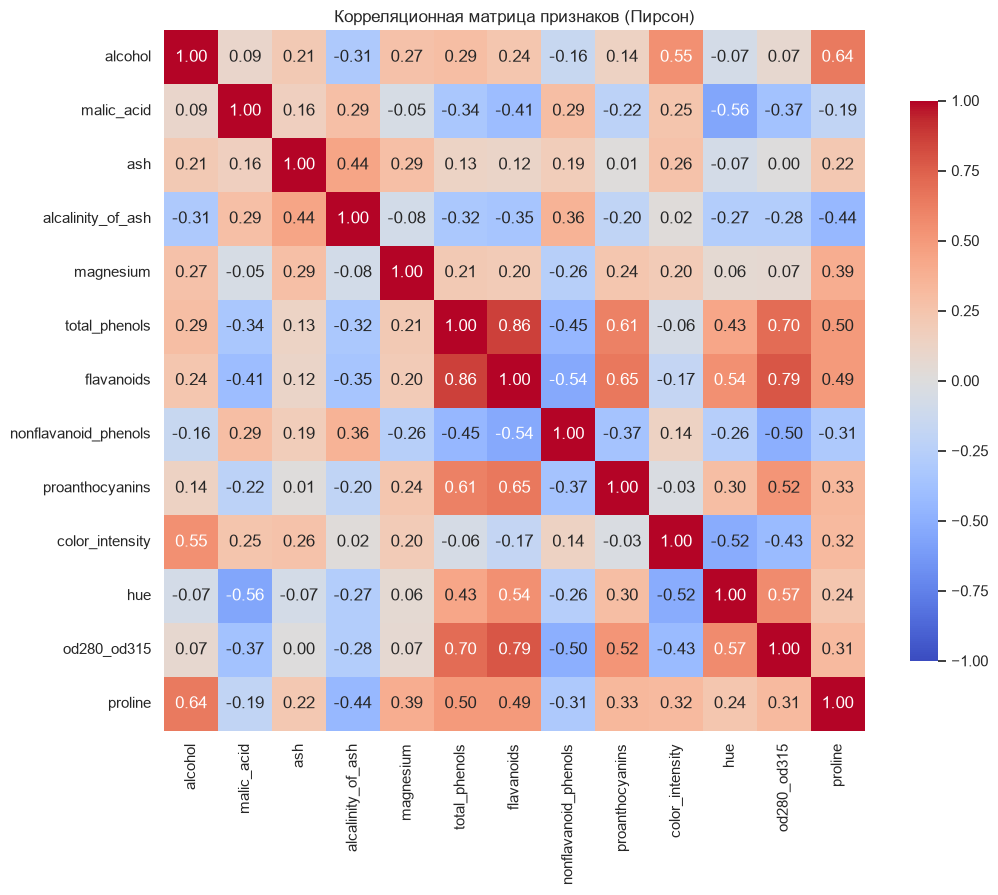

,CV,max|r| с другими,Вклад в PC1+PC2,ANOVA F,ANOVA p,MI с классом
flavanoids,0.4922,0.8646,0.1169,233.9259,0.0,0.6676
total_phenols,0.2727,0.8646,0.1032,93.7330,0.0,0.4016
color_intensity,0.4583,0.5464,0.1025,120.6640,0.0,0.5483
od280_od315,0.2719,0.7872,0.1018,189.9723,0.0,0.5162
proline,0.4216,0.6437,0.0999,207.9204,0.0,0.5774
alcohol,0.0624,0.6437,0.0947,135.0776,0.0,0.4743
hue,0.2387,0.5655,0.0845,101.3168,0.0,0.4664
proanthocyanins,0.3598,0.6527,0.0647,30.2714,0.0,0.3054
nonflavanoid_phenols,0.3439,0.5379,0.0585,27.5754,0.0,0.1210
malic_acid,0.4782,0.5613,0.0568,36.9434,0.0,0.2824


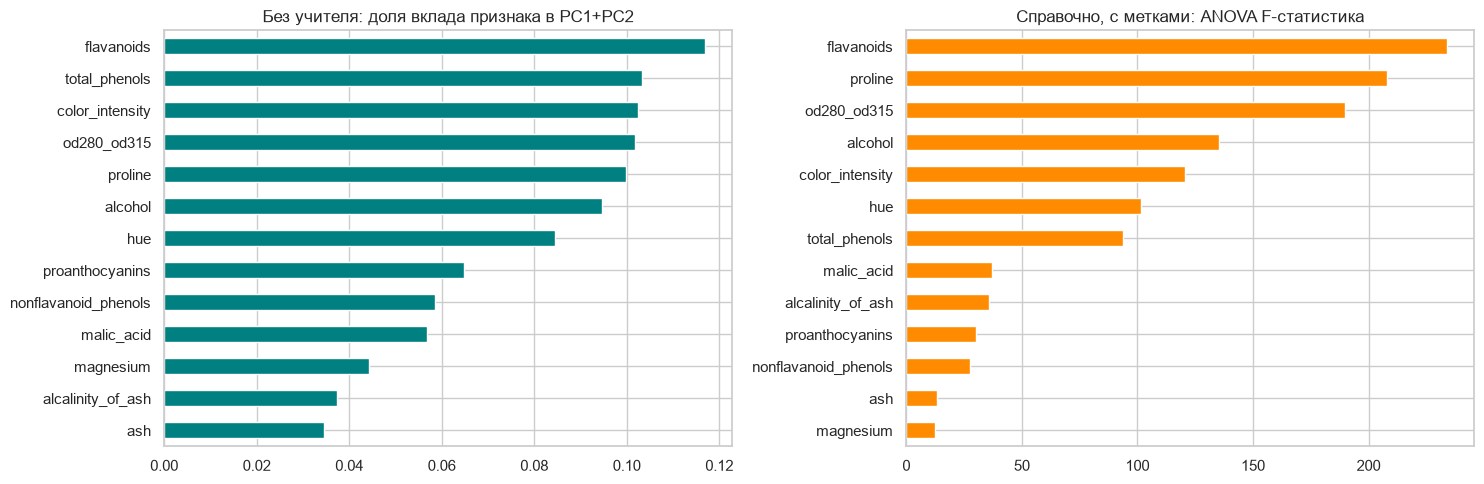

In [5]:
corr = X.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8})
plt.title("Корреляционная матрица признаков (Пирсон)")
plt.tight_layout()
savefig("correlation")
plt.show()

X_std_tmp = StandardScaler().fit_transform(X)
pca_full = PCA(random_state=SEED).fit(X_std_tmp)
loadings = pd.DataFrame(pca_full.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
pca_contrib = (loadings ** 2 * pca_full.explained_variance_ratio_[:2]).sum(axis=1) / pca_full.explained_variance_ratio_[:2].sum()

f_val, f_p = f_classif(X, y_true)
mi = mutual_info_classif(X, y_true, random_state=SEED)
max_abs_corr = corr.abs().where(~np.eye(len(FEATURES), dtype=bool)).max()

importance = pd.DataFrame({
    "CV": X.std() / X.mean(),
    "max|r| с другими": max_abs_corr,
    "Вклад в PC1+PC2": pca_contrib,
    "ANOVA F": f_val,
    "ANOVA p": f_p,
    "MI с классом": mi,
}, index=FEATURES).sort_values("Вклад в PC1+PC2", ascending=False)
display(importance.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance["Вклад в PC1+PC2"].sort_values().plot.barh(ax=axes[0], color="teal")
axes[0].set_title("Без учителя: доля вклада признака в PC1+PC2")
importance["ANOVA F"].sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Справочно, с метками: ANOVA F-статистика")
plt.tight_layout()
savefig("feature_importance")
plt.show()

Значимость признаков оценивалась двумя способами.

**Без учителя** (именно так оцениваются признаки при кластеризации, где меток нет):
- *Коэффициент вариации*: почти постоянный признак не может разделять группы. Таких признаков нет — минимальный CV у `alcohol` (0.06), но его абсолютный размах (11.0–14.8 %) содержательно велик.
- *Корреляции*: сильно связаны `flavanoids`–`total_phenols` (r = 0.86) и `flavanoids`–`od280_od315` (r = 0.79). Они частично дублируют друг друга (все отражают содержание фенольных соединений), что добавляет вес этому направлению в евклидовом расстоянии.
- *Вклад в PC1+PC2*: наибольший у `flavanoids` (0.117), `total_phenols`, `color_intensity`, `od280_od315`, `proline` (≈ 0.10 каждый), наименьший — у `ash` (0.035) и `alcalinity_of_ash` (0.038). Именно первые признаки формируют главные направления разброса данных.

**Справочно, с метками** (ANOVA F и взаимная информация MI с `class`): наиболее информативны `flavanoids` (F = 233.9, MI = 0.67), `proline` (F = 207.9), `od280_od315` (F = 190.0), `alcohol` (F = 135.1), `color_intensity` (F = 120.7); наименее — `magnesium` (F = 12.4) и `ash` (F = 13.3, MI = 0.08). Все p-value < 0.05.

**Решение о составе признаков:** в кластеризации используются **все 13 признаков**. Ни один не является константным или шумовым по всем критериям; удаление коррелированных признаков (`total_phenols`, `od280_od315`) мало влияет на результат, а слабые признаки (`ash`, `magnesium`) после стандартизации имеют такой же масштаб, но малую межгрупповую дисперсию, и потому слабо влияют на расстояния. Для матрицы диаграмм рассеивания отбираются 6 наиболее информативных признаков.

### 2.4. Анализ выбросов

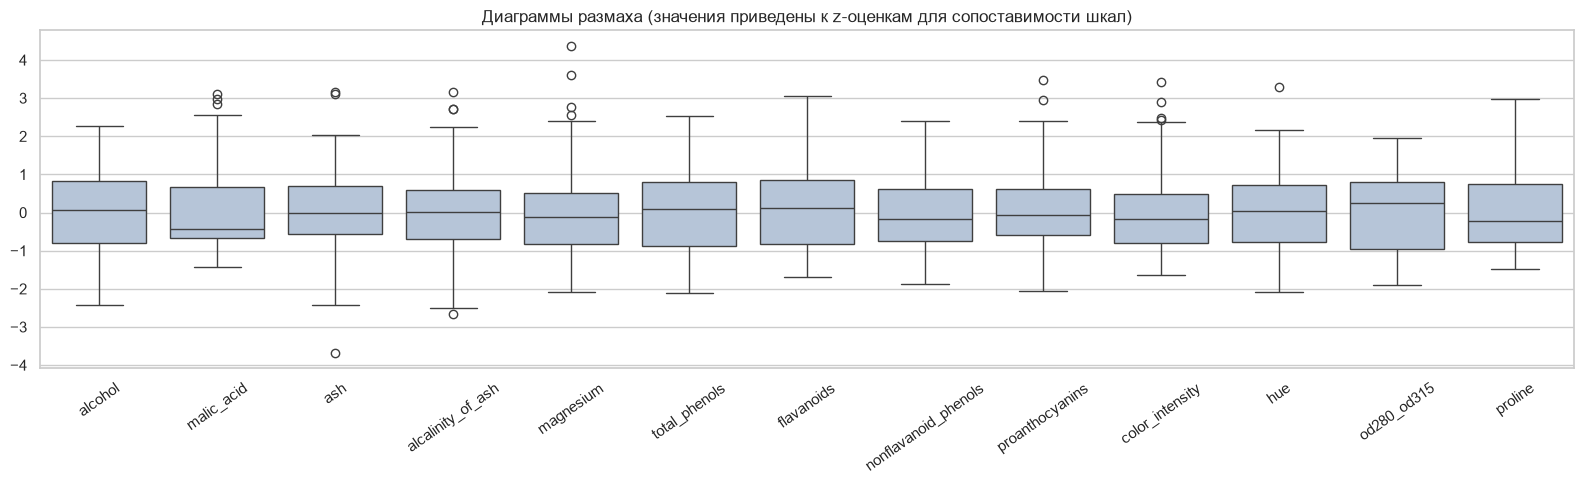

,Нижняя граница,Верхняя граница,Выбросов IQR,Выбросов |z|>3
alcohol,10.390,15.650,0,0
malic_acid,-0.617,5.302,3,1
ash,1.689,3.079,3,3
alcalinity_of_ash,10.750,27.950,4,1
magnesium,59.500,135.500,4,2
total_phenols,0.156,4.386,0,0
flavanoids,-1.300,5.380,0,1
nonflavanoid_phenols,0.019,0.689,0,0
proanthocyanins,0.200,3.000,2,1
color_intensity,-1.250,10.670,4,1


Строк хотя бы с одним IQR-выбросом: 17 (9.6%)
Строк хотя бы с одним |z|>3: 10 (5.6%)
Многомерные выбросы (Махаланобис > 5.88, χ²(13), p<0.001): 6


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,class,признаки |z|>3,Махаланобис
25,13.05,2.05,3.22,25.0,124.0,2.63,2.68,0.47,1.92,3.58,1.13,3.20,830.0,1,ash,3.86
59,12.37,0.94,1.36,10.6,88.0,1.98,0.57,0.28,0.42,1.95,1.05,1.82,520.0,2,ash,5.26
69,12.21,1.19,1.75,16.8,151.0,1.85,1.28,0.14,2.50,2.85,1.28,3.07,718.0,2,magnesium,6.22
73,12.99,1.67,2.60,30.0,139.0,3.30,2.89,0.21,1.96,3.35,1.31,3.50,985.0,2,alcalinity_of_ash,6.16
95,12.47,1.52,2.20,19.0,162.0,2.50,2.27,0.32,3.28,2.60,1.16,2.63,937.0,2,magnesium,6.18
110,11.46,3.74,1.82,19.5,107.0,3.18,2.58,0.24,3.58,2.90,0.75,2.81,562.0,2,proanthocyanins,5.93
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0,2,hue,5.19
121,11.56,2.05,3.23,28.5,119.0,3.18,5.08,0.47,1.87,6.00,0.93,3.69,465.0,2,"ash, flavanoids",7.66
123,13.05,5.80,2.13,21.5,86.0,2.62,2.65,0.30,2.01,2.60,0.73,3.10,380.0,2,malic_acid,4.68
158,14.34,1.68,2.70,25.0,98.0,2.80,1.31,0.53,2.70,13.00,0.57,1.96,660.0,3,color_intensity,6.05


In [6]:
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES), ax=ax, color="lightsteelblue")
ax.set_title("Диаграммы размаха (значения приведены к z-оценкам для сопоставимости шкал)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
savefig("boxplots")
plt.show()

q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_mask = (X < low) | (X > high)
z = (X - X.mean()) / X.std()
z_mask = z.abs() > 3

outlier_table = pd.DataFrame({
    "Нижняя граница": low, "Верхняя граница": high,
    "Выбросов IQR": iqr_mask.sum(), "Выбросов |z|>3": z_mask.sum(),
})
display(outlier_table.round(3))

rows_iqr = iqr_mask.any(axis=1)
rows_z = z_mask.any(axis=1)
print(f"Строк хотя бы с одним IQR-выбросом: {rows_iqr.sum()} ({rows_iqr.mean():.1%})")
print(f"Строк хотя бы с одним |z|>3: {rows_z.sum()} ({rows_z.mean():.1%})")

X_std_tmp = StandardScaler().fit_transform(X)
center_dist = np.sqrt((X_std_tmp ** 2).sum(axis=1))
cov_inv = np.linalg.inv(np.cov(X_std_tmp, rowvar=False))
mahal = np.sqrt(np.einsum("ij,jk,ik->i", X_std_tmp, cov_inv, X_std_tmp))
from scipy.stats import chi2
mahal_thr = np.sqrt(chi2.ppf(0.999, df=len(FEATURES)))
mahal_mask = mahal > mahal_thr
print(f"Многомерные выбросы (Махаланобис > {mahal_thr:.2f}, χ²(13), p<0.001): {mahal_mask.sum()}")

extreme = df.loc[rows_z, FEATURES + [TARGET]].copy()
extreme["признаки |z|>3"] = z_mask[rows_z].apply(lambda r: ", ".join(r.index[r]), axis=1)
extreme["Махаланобис"] = mahal[rows_z.to_numpy()].round(2)
display(extreme)

- По правилу **1.5·IQR** найдено 17 строк (9.6 %) хотя бы с одним выбросом. Для 13 признаков это ожидаемо даже без аномалий: при асимметричных распределениях (`magnesium`, `color_intensity`, `malic_acid`) правило 1.5·IQR срабатывает на естественном правом хвосте.
- Более строгий критерий **|z| > 3** отмечает 10 строк (5.6 %).
- **Многомерный критерий — расстояние Махаланобиса** (порог √χ²₀.₉₉₉(13) = 5.88) учитывает корреляции признаков и показывает, насколько объект нетипичен по совокупности всех признаков; таких объектов 6.

Принятое решение: **удаляются объекты, которые одновременно имеют |z| > 3 хотя бы по одному признаку и являются многомерными выбросами по Махаланобису** — индексы 69, 73, 95, 110, 121, 158 (6 объектов, 3.4 % выборки). Например, объект 158: `color_intensity` = 13.0 (максимум выборки, z ≈ 3.4); объект 95: `magnesium` = 162; объект 121: `flavanoids` = 5.08 при `ash` = 3.23. Остальные «выбросы» (например, 25, 59, 115, 123) экстремальны лишь по одному признаку, но типичны в многомерном пространстве — это естественная изменчивость, их удаление сократило бы выборку без пользы.

Удаление нужно потому, что K-means и метод Ward минимизируют сумму квадратов отклонений: одиночный далёкий объект сильно смещает центр кластера. Метки классов при принятии решения не использовались.

In [7]:
drop_mask = rows_z.to_numpy() & mahal_mask
print("Удаляются объекты (|z|>3 по признаку и многомерный выброс по Махаланобису):", list(df.index[drop_mask]))

data = df.loc[~drop_mask].reset_index(drop=True)
X = data[FEATURES].copy()
y_true = data[TARGET].astype(int).to_numpy()
print("Осталось объектов:", len(X))
display(data[TARGET].value_counts().sort_index().rename("Объектов").to_frame().T)

Удаляются объекты (|z|>3 по признаку и многомерный выброс по Махаланобису): [69, 73, 95, 110, 121, 158]
Осталось объектов: 172


class,1,2,3
Объектов,59,66,47


После удаления остаётся **172 объекта** (классы 59 / 66 / 47). Все удалённые объекты, кроме одного, относятся ко 2-му сорту — он самый неоднородный в выборке.

### 2.5. Проверка условий применимости кластеризации

1. **Отсутствие классов.** Исходная метка `class` известна, но в кластеризации она не используется: модели получают только матрицу признаков `X_scaled`. Метки применяются исключительно для внешней оценки качества — это стандартная постановка эксперимента, позволяющая проверить, восстанавливают ли алгоритмы естественные группы.
2. **Осмысленность кластеризации.** Группировка вин по химическому составу имеет практический смысл: выделение типов вин (сортов, стилей) без предварительной экспертной разметки. Многовершинные гистограммы и статистика Хопкинса (раздел 3.3) подтверждают, что данные не являются равномерным «облаком».
3. **Отсутствие выбросов.** Грубые многомерные выбросы удалены (раздел 2.4); после этого нет объектов, способных сместить центры.
4. **Числовые признаки, сопоставимые шкалы** — обеспечиваются стандартизацией (раздел 3).

## 3. Предобработка данных

### 3.1. Стандартизация

Используется **`StandardScaler`**: $z = \dfrac{x - \mu}{\sigma}$, где μ и σ — среднее и стандартное отклонение признака по выборке.

**Обоснование выбора:**
- Признаки измеряются в разных единицах и различаются по масштабу на 3–4 порядка (`proline` ~ 10³, `hue` ~ 1). K-means, Ward и DBSCAN используют евклидово расстояние, поэтому без масштабирования кластеризация фактически шла бы по одному признаку.
- После стандартизации каждый признак вносит в расстояние вклад, пропорциональный своей *относительной* изменчивости, а σ = 1 делает параметр ε у DBSCAN интерпретируемым (в единицах стандартного отклонения).
- **MinMaxScaler** не выбран: он чувствителен к экстремальным значениям (один большой `magnesium` сжимает все остальные значения в узкий диапазон). **RobustScaler** (медиана/IQR) нужен при большом числе выбросов, а после удаления 6 многомерных выбросов данные достаточно «чистые». Стандартизация также рекомендована в методических указаниях к работе.

Масштабирование применяется ко всем 13 признакам `FEATURES`; столбец `class` не передаётся.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[FEATURES])
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)

check = pd.DataFrame({"mean до": X.mean(), "std до": X.std(ddof=0), "mean после": X_scaled_df.mean(), "std после": X_scaled_df.std(ddof=0)})
display(check.round(4))
print("Матрица для кластеризации:", X_scaled.shape)

,mean до,std до,mean после,std после
alcohol,13.0179,0.7977,0.0,1.0
malic_acid,2.3490,1.1205,0.0,1.0
ash,2.3659,0.2609,0.0,1.0
alcalinity_of_ash,19.3680,3.1824,-0.0,1.0
magnesium,98.7093,12.6334,0.0,1.0
total_phenols,2.2774,0.6204,-0.0,1.0
flavanoids,2.0105,0.9796,-0.0,1.0
nonflavanoid_phenols,0.3634,0.1232,0.0,1.0
proanthocyanins,1.5540,0.5319,0.0,1.0
color_intensity,5.0560,2.2475,-0.0,1.0


Матрица для кластеризации: (172, 13)


Проверка результата: после преобразования у всех 13 признаков среднее равно 0, а стандартное отклонение — 1 (с точностью до округления). Форма распределений при этом не меняется — стандартизация является линейным преобразованием. Итоговая матрица для кластеризации — `X_scaled` размером 172 × 13.

### 3.2. Матрица диаграмм рассеивания

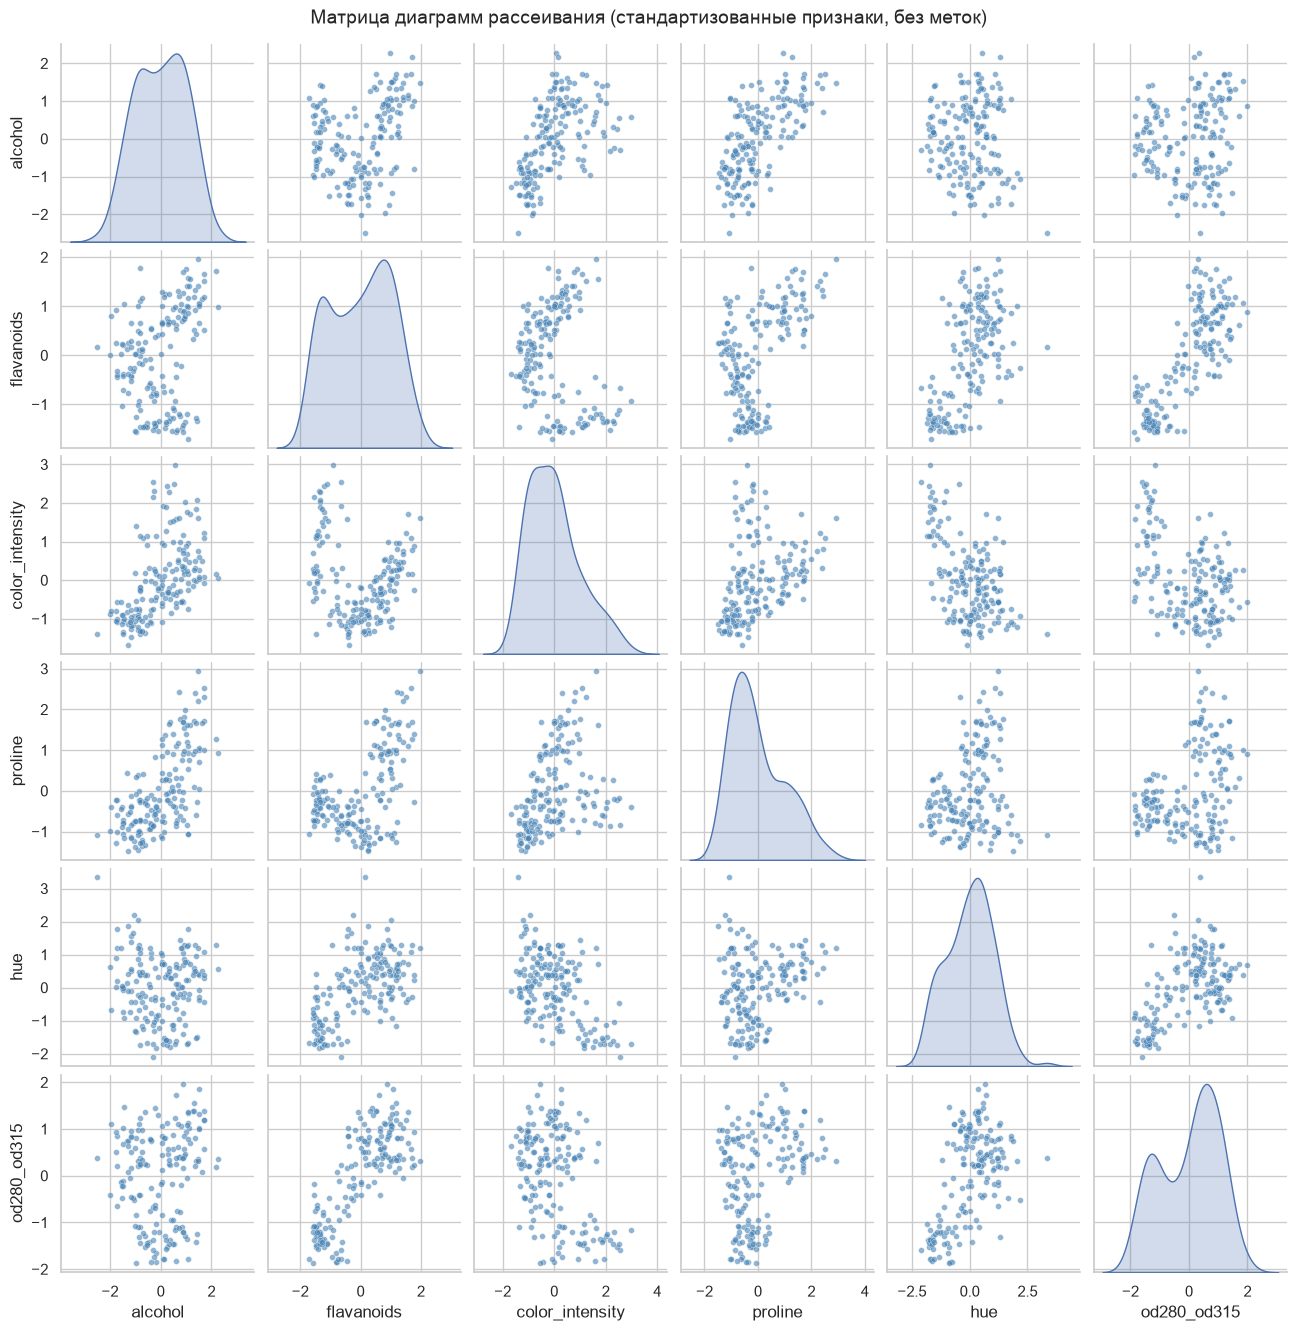

In [9]:
SCATTER_FEATURES = ["alcohol", "flavanoids", "color_intensity", "proline", "hue", "od280_od315"]
g = sns.pairplot(X_scaled_df[SCATTER_FEATURES], diag_kind="kde", plot_kws={"s": 18, "alpha": 0.6, "color": "steelblue"}, height=2.2)
g.figure.suptitle("Матрица диаграмм рассеивания (стандартизованные признаки, без меток)", y=1.01, fontsize=14)
savefig("scatter_matrix")
plt.show()

Матрица построена по 6 наиболее информативным признакам (`alcohol`, `flavanoids`, `color_intensity`, `proline`, `hue`, `od280_od315`) без раскраски по классам — так, как видит данные алгоритм кластеризации.

- На парах `flavanoids`–`color_intensity`, `proline`–`flavanoids`, `hue`–`color_intensity`, `alcohol`–`proline` отчётливо видны **три сгущения точек**. Например, в координатах `flavanoids`–`color_intensity`: группа с низкими флавоноидами и высокой интенсивностью цвета, группа с высокими флавоноидами и средней интенсивностью цвета, группа с низкой интенсивностью цвета.
- На диагонали (KDE) у `flavanoids`, `od280_od315`, `proline`, `alcohol` — две-три вершины.
- **Форма групп** близка к выпуклой, эллипсоидной; сгущения сопоставимы по размеру и плотности; длинных изогнутых или вложенных структур нет.
- **Разделённость** умеренная: между группами есть «мостики» из промежуточных объектов, полностью пустых промежутков нет.
- Пары `flavanoids`–`od280_od315` вытянуты вдоль диагонали — следствие сильной корреляции (r = 0.79).

**Ограничения:** двумерные проекции не показывают структуру в 13-мерном пространстве целиком — группы, разделённые по сочетанию многих признаков, могут перекрываться на любой отдельной паре, а кажущееся слияние в проекции не означает слияния в полном пространстве. Поэтому дополнительно используется PCA.

### 3.3. Структура данных в пространстве главных компонент и тенденция к кластеризации

Доля объяснённой дисперсии PC1..PC3: [0.3772 0.203  0.1044] | сумма PC1+PC2: 0.5803 | PC1..PC3: 0.6847


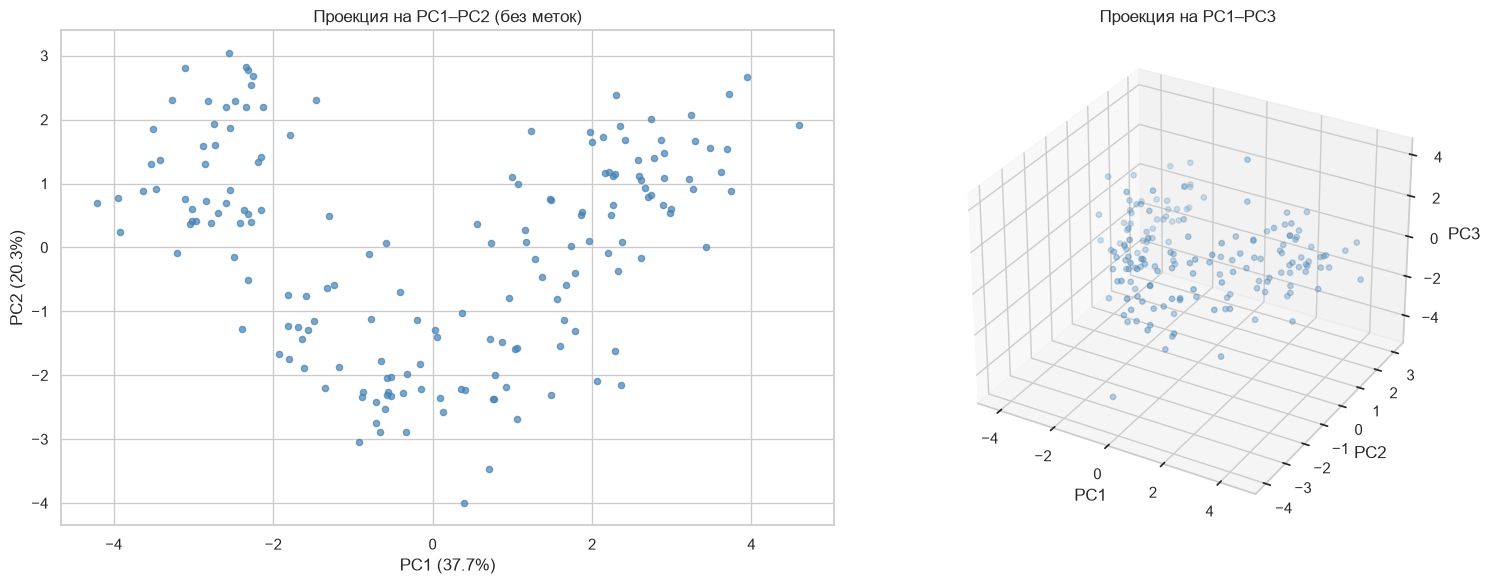

Статистика Хопкинса (20 повторов): 0.692 ± 0.018


In [10]:
pca = PCA(n_components=3, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print("Доля объяснённой дисперсии PC1..PC3:", evr.round(4), "| сумма PC1+PC2:", round(evr[:2].sum(), 4), "| PC1..PC3:", round(evr.sum(), 4))

fig = plt.figure(figsize=(16, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(X_pca[:, 0], X_pca[:, 1], s=20, alpha=0.7, color="steelblue")
ax1.set_xlabel(f"PC1 ({evr[0]:.1%})")
ax1.set_ylabel(f"PC2 ({evr[1]:.1%})")
ax1.set_title("Проекция на PC1–PC2 (без меток)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], s=15, alpha=0.7, color="steelblue")
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_zlabel("PC3")
ax2.set_title("Проекция на PC1–PC3")
plt.tight_layout()
savefig("pca_structure")
plt.show()

hopkins_rng = np.random.default_rng(SEED)
def hopkins(data, m=None):
    n, d = data.shape
    m = m or int(0.1 * n)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    idx = hopkins_rng.choice(n, m, replace=False)
    u_pts = hopkins_rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, d))
    u = nn.kneighbors(u_pts, n_neighbors=1)[0].ravel()
    w = nn.kneighbors(data[idx], n_neighbors=2)[0][:, 1]
    return u.sum() / (u.sum() + w.sum())

hopkins_values = [hopkins(X_scaled) for _ in range(20)]
print(f"Статистика Хопкинса (20 повторов): {np.mean(hopkins_values):.3f} ± {np.std(hopkins_values):.3f}")

- Первые две главные компоненты объясняют 58.0 % дисперсии (37.7 % + 20.3 %), три компоненты — 68.5 %. В проекции PC1–PC2 видна **«подкова» из трёх сгущений**: левое верхнее, нижнее центральное и правое верхнее. Крайние группы разделены хорошо, центральная соединена с ними переходными точками.
- **Статистика Хопкинса** H = 0.692 ± 0.018. Для равномерно распределённых данных H ≈ 0.5, для выраженной кластерной структуры H → 1. Значение около 0.7 говорит о **заметной тенденции к кластеризации**: данные не случайны, но кластеры не изолированы (что согласуется со скаттер-матрицей).

## 4. Выбор методов кластеризации

По визуальному анализу (скаттер-матрица, PCA): **предположительно 3 кластера, выпуклые, близкие к эллипсоидным, сопоставимые по размеру и плотности, разделённые не полностью** (есть переходные объекты).

1. **K-means** — оптимален для компактных выпуклых кластеров близкого размера, так как минимизирует внутрикластерную сумму квадратов и задаёт кластеры как области Вороного вокруг центроидов. Его недостатки (необходимость задать k, чувствительность к выбросам и инициализации) закрываются методом локтя/силуэтом, удалением выбросов и `n_init=10`.
2. **Иерархическая агломеративная кластеризация (Ward)** — тоже ориентирована на компактные группы (на каждом шаге объединяет пару, минимально увеличивающую внутрикластерную сумму квадратов), но не зависит от случайной инициализации и даёт дендрограмму, по которой видна вложенная структура данных и обоснованно выбирается уровень среза. Сравнение двух методов с одинаковым критерием компактности, но разной процедурой (итеративное уточнение против жадного объединения) позволяет проверить устойчивость найденных групп.

**Почему не DBSCAN в качестве основного:** кластеры имеют близкую плотность и соединены «мостиками» из переходных точек; в 13-мерном пространстве расстояния между точками выравниваются, и плотностной метод либо сливает группы, либо объявляет шумом значительную долю объектов. Это проверено в разделе 6.3 — DBSCAN исследован как дополнительный метод.
**Почему не Gaussian Mixture:** при 172 объектах и 13 признаках модель с полными ковариациями имеет 3·(13 + 91) + 2 = 314 параметров — больше, чем объектов, что ведёт к неустойчивой оценке.

In [11]:
def n_clusters_of(labels):
    return len(set(labels) - {-1})

def internal_metrics(data, labels):
    mask = labels != -1
    k = n_clusters_of(labels)
    if k < 2 or mask.sum() <= k:
        return {"Silhouette": np.nan, "Calinski-Harabasz": np.nan, "Davies-Bouldin": np.nan}
    return {
        "Silhouette": silhouette_score(data[mask], labels[mask]),
        "Calinski-Harabasz": calinski_harabasz_score(data[mask], labels[mask]),
        "Davies-Bouldin": davies_bouldin_score(data[mask], labels[mask]),
    }

def pair_counts(a, b):
    cont = pd.crosstab(a, b).to_numpy()
    same_both = sum(comb(int(v), 2) for v in cont.ravel())
    same_a = sum(comb(int(v), 2) for v in cont.sum(axis=1))
    same_b = sum(comb(int(v), 2) for v in cont.sum(axis=0))
    total = comb(len(a), 2)
    tp = same_both
    fn = same_a - tp
    fp = same_b - tp
    tn = total - tp - fp - fn
    return tp, fp, fn, tn

def jaccard_pairs(a, b):
    tp, fp, fn, _ = pair_counts(a, b)
    return tp / (tp + fp + fn)

def matched_accuracy(a, b):
    cont = pd.crosstab(a, b)
    r, c = linear_sum_assignment(-cont.to_numpy())
    return cont.to_numpy()[r, c].sum() / len(a)

def external_metrics(true, labels):
    mask = labels != -1
    t, l = true[mask], labels[mask]
    return {
        "Rand": rand_score(t, l),
        "ARI": adjusted_rand_score(t, l),
        "Jaccard (пары)": jaccard_pairs(t, l),
        "Fowlkes-Mallows": fowlkes_mallows_score(t, l),
        "NMI": normalized_mutual_info_score(t, l),
        "AMI": adjusted_mutual_info_score(t, l),
        "Homogeneity": homogeneity_score(t, l),
        "Completeness": completeness_score(t, l),
        "V-measure": v_measure_score(t, l),
        "Accuracy (Венгерский алгоритм)": matched_accuracy(t, l),
    }

def cluster_centers(data, labels):
    ids = sorted(set(labels) - {-1})
    return ids, np.vstack([data[labels == c].mean(axis=0) for c in ids])

def compactness_table(data, labels):
    ids, centers = cluster_centers(data, labels)
    rows = []
    for c, center in zip(ids, centers):
        pts = data[labels == c]
        d_center = np.linalg.norm(pts - center, axis=1)
        pair = pdist(pts) if len(pts) > 1 else np.array([0.0])
        rows.append({
            "Кластер": c,
            "Объектов": len(pts),
            "Ср. расст. до центра": d_center.mean(),
            "Макс. расст. до центра": d_center.max(),
            "Ср. попарное расст.": pair.mean(),
            "Диаметр": pair.max(),
            "SSE (инерция)": (d_center ** 2).sum(),
        })
    return pd.DataFrame(rows).set_index("Кластер")

def separation_tables(data, labels):
    ids, centers = cluster_centers(data, labels)
    center_d = pd.DataFrame(cdist(centers, centers), index=ids, columns=ids)
    single_d = pd.DataFrame(0.0, index=ids, columns=ids)
    avg_d = pd.DataFrame(0.0, index=ids, columns=ids)
    for a, b in combinations(ids, 2):
        d = cdist(data[labels == a], data[labels == b])
        single_d.loc[a, b] = single_d.loc[b, a] = d.min()
        avg_d.loc[a, b] = avg_d.loc[b, a] = d.mean()
    return center_d, single_d, avg_d

def dunn_index(data, labels):
    ids = sorted(set(labels) - {-1})
    diam = max(pdist(data[labels == c]).max() for c in ids if (labels == c).sum() > 1)
    sep = min(cdist(data[labels == a], data[labels == b]).min() for a, b in combinations(ids, 2))
    return sep / diam

Вспомогательные функции:
- `n_clusters_of` — фактическое число кластеров без учёта шумовой метки −1;
- `internal_metrics` — Silhouette, Calinski–Harabasz, Davies–Bouldin; вычисляются только по нешумовым объектам и **возвращают NaN, если кластеров меньше двух** (метрики для одного кластера не определены);
- `external_metrics` — сравнение исходных классов и меток кластеров; Jaccard считается по парам объектов (TP — пары в одном классе и одном кластере), поэтому он инвариантен к нумерации кластеров; `matched_accuracy` сопоставляет кластеры классам Венгерским алгоритмом;
- `cluster_centers` — центры как среднее объектов кластера (для Ward и DBSCAN, которые центров не возвращают);
- `compactness_table` — компактность: среднее и максимальное расстояние до центра, среднее попарное расстояние, диаметр, SSE;
- `separation_tables` — расстояния между кластерами тремя способами: между центрами, минимальное (single) и среднее (average) между объектами;
- `dunn_index` — отношение минимального межкластерного расстояния к максимальному диаметру.

## 5. Подбор числа кластеров

### 5.1. K-means: метод локтя и силуэтный анализ
Перебираются k = 2…10. Для каждого k обучается `KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)`, результаты сохраняются в таблицу `kmeans_search` и `results/kmeans_k_search.csv`. Положение локтя определяется автоматически как точка кривой инерции, максимально удалённая от хорды, соединяющей её концы.

,Инерция,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (справочно),"Падение инерции, %"
k,,,,,,
2,1575.9560,0.2664,71.1996,1.4731,0.4262,NaN
3,1182.4629,0.2963,75.2868,1.3280,0.9311,24.9685
4,1094.4626,0.2534,58.4087,1.7325,0.7654,7.4421
5,1036.7731,0.2269,48.2919,1.7221,0.6808,5.2710
6,968.3349,0.1872,43.4627,1.8495,0.5581,6.6011
7,922.3710,0.1428,39.1651,1.9152,0.4344,4.7467
8,883.4078,0.1423,35.8717,1.9441,0.3826,4.2242
9,829.9851,0.1401,34.5157,1.8402,0.3865,6.0473
10,809.5307,0.1426,31.7177,1.7571,0.3158,2.4644


Локоть (максимальное расстояние до хорды): 3 | максимум силуэта: 3


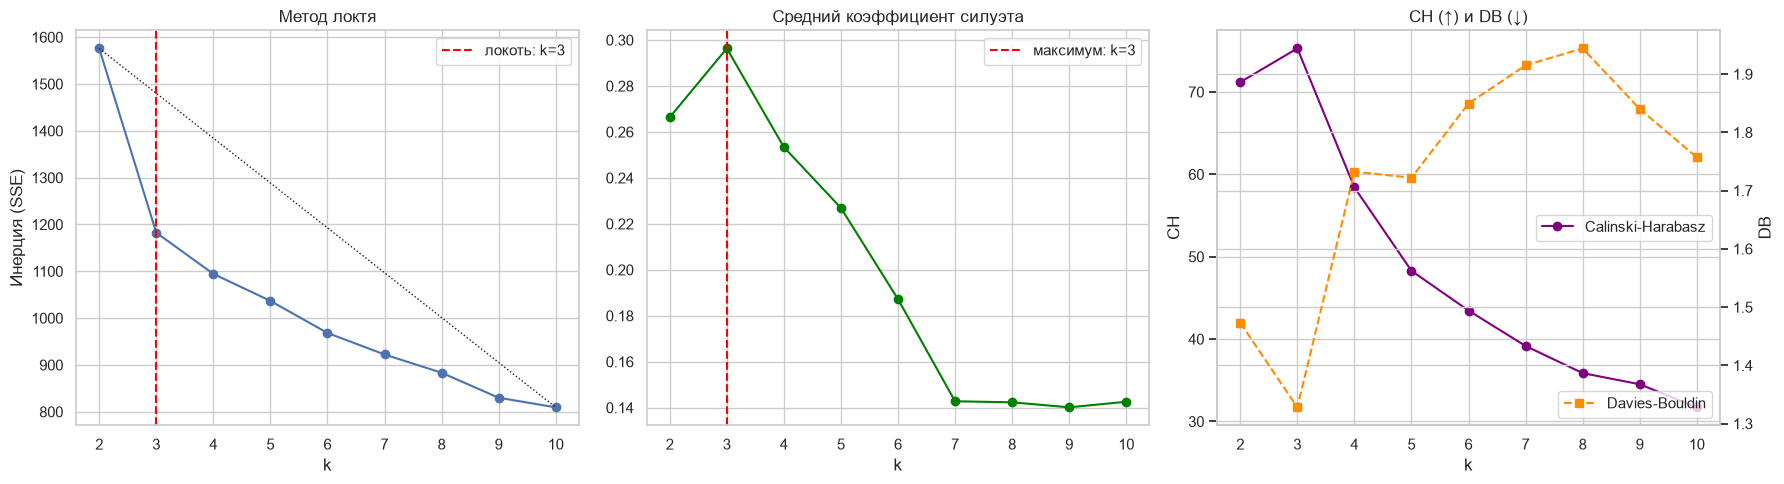

In [12]:
K_RANGE = range(2, 11)
kmeans_search = []
kmeans_labels_by_k = {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    lab = km.fit_predict(X_scaled)
    kmeans_labels_by_k[k] = lab
    kmeans_search.append({"k": k, "Инерция": km.inertia_, **internal_metrics(X_scaled, lab), "ARI (справочно)": adjusted_rand_score(y_true, lab)})
kmeans_search = pd.DataFrame(kmeans_search).set_index("k")
kmeans_search["Падение инерции, %"] = (-kmeans_search["Инерция"].pct_change() * 100)
kmeans_search.to_csv(RES_DIR / "kmeans_k_search.csv")
display(kmeans_search.round(4))

inertia = kmeans_search["Инерция"].to_numpy()
ks = np.array(list(K_RANGE))
p1, p2 = np.array([ks[0], inertia[0]]), np.array([ks[-1], inertia[-1]])
v, w = p2 - p1, np.c_[ks, inertia] - p1
dist_to_line = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
elbow_k = int(ks[np.argmax(dist_to_line)])
sil_k = int(kmeans_search["Silhouette"].idxmax())
print("Локоть (максимальное расстояние до хорды):", elbow_k, "| максимум силуэта:", sil_k)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(ks, inertia, "o-")
axes[0].plot([ks[0], ks[-1]], [inertia[0], inertia[-1]], "k:", lw=1)
axes[0].axvline(elbow_k, color="red", ls="--", label=f"локоть: k={elbow_k}")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция (SSE)")
axes[0].legend()
axes[1].plot(ks, kmeans_search["Silhouette"], "o-", color="green")
axes[1].axvline(sil_k, color="red", ls="--", label=f"максимум: k={sil_k}")
axes[1].set_title("Средний коэффициент силуэта")
axes[1].set_xlabel("k")
axes[1].legend()
ax_ch = axes[2]
ax_ch.plot(ks, kmeans_search["Calinski-Harabasz"], "o-", color="purple", label="Calinski-Harabasz")
ax_ch.set_xlabel("k")
ax_ch.set_ylabel("CH")
ax_db = ax_ch.twinx()
ax_db.plot(ks, kmeans_search["Davies-Bouldin"], "s--", color="darkorange", label="Davies-Bouldin")
ax_db.set_ylabel("DB")
ax_ch.set_title("CH (↑) и DB (↓)")
ax_ch.legend(loc="center right")
ax_db.legend(loc="lower right")
plt.tight_layout()
savefig("kmeans_elbow_silhouette")
plt.show()

- **Метод локтя.** Инерция (SSE — сумма квадратов расстояний объектов до центров своих кластеров) монотонно убывает: 1575.96 (k = 2) → 1182.46 (k = 3) → 1094.46 (k = 4) → … → 809.53 (k = 10). Переход 2 → 3 уменьшает инерцию на 25.0 %, а каждый следующий шаг — лишь на 2.5–7.4 %. Излом («локоть») — **k = 3**.
- **Силуэт** максимален при **k = 3** (0.296); при k = 2 — 0.266, при k = 4 — 0.253, далее быстро падает до ≈ 0.14.
- **Calinski–Harabasz** максимален при k = 3 (75.29), **Davies–Bouldin** минимален при k = 3 (1.328).

Все четыре критерия согласованно указывают на **k = 3**. Абсолютное значение силуэта 0.30 по шкале Кауфмана–Руссо (0.26–0.50) соответствует **слабой, но реальной** кластерной структуре — кластеры частично перекрываются, что видно и на PCA.

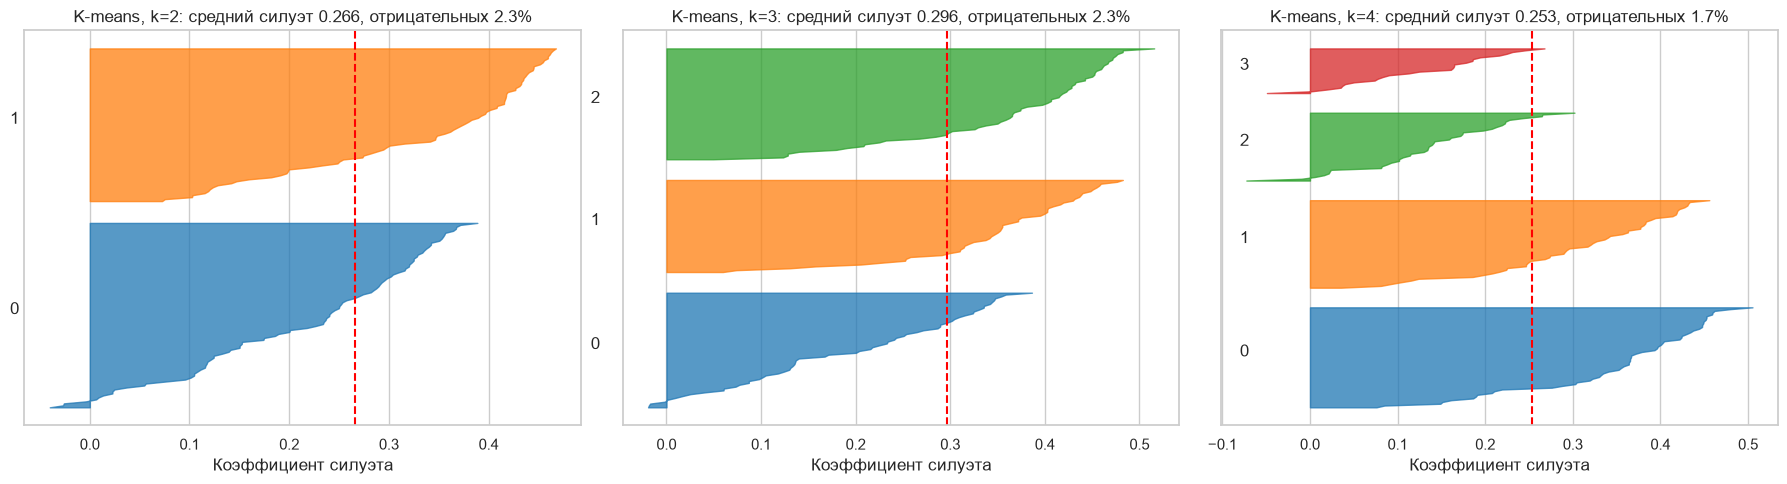

In [13]:
def silhouette_plot(ax, data, labels, title):
    vals = silhouette_samples(data, labels)
    y_low = 10
    for i, c in enumerate(sorted(set(labels))):
        v = np.sort(vals[labels == c])
        ax.fill_betweenx(np.arange(y_low, y_low + len(v)), 0, v, alpha=0.75, color=plt.cm.tab10(i))
        ax.text(-0.08, y_low + len(v) / 2, str(c))
        y_low += len(v) + 10
    ax.axvline(vals.mean(), color="red", ls="--")
    ax.set_title(f"{title}: средний силуэт {vals.mean():.3f}, отрицательных {np.mean(vals < 0):.1%}")
    ax.set_xlabel("Коэффициент силуэта")
    ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [2, 3, 4]):
    silhouette_plot(ax, X_scaled, kmeans_labels_by_k[k], f"K-means, k={k}")
plt.tight_layout()
savefig("silhouette_kmeans")
plt.show()

Силуэтные диаграммы для k = 2, 3, 4:
- при **k = 3** все три кластера сопоставимы по толщине (50–62 объекта), в каждом кластере значительная часть объектов имеет силуэт выше среднего, максимальные значения достигают 0.39–0.52; отрицательный силуэт только у 2.3 % объектов (4 пограничных объекта кластера 0);
- при k = 2 доля отрицательных та же (2.3 %), но кластер 0 содержит длинный «хвост» объектов с силуэтом около 0 — в нём объединены две разнородные группы;
- при k = 4 отрицательных объектов меньше (1.7 %), но появляются два тонких кластера (2 и 3), у которых почти все значения ниже среднего и не превышают 0.27–0.30 — одна естественная группа разрезана искусственно, и средний силуэт падает до 0.253.

Таким образом, k = 3 даёт наибольший средний силуэт и наиболее равномерные по качеству кластеры.

### 5.2. Иерархическая кластеризация: дендрограмма
Матрица связей строится функцией `scipy.cluster.hierarchy.linkage(X_scaled, method="ward", metric="euclidean")`. Высота каждого слияния на дендрограмме — расстояние Ward (рост внутрикластерной суммы квадратов при объединении).

,0,1,2,3,4,5,6,7,8,9
k,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.00
"Высота слияния, ведущего к k кластерам",34.973,28.046,13.080,12.318,11.008,10.351,9.379,8.790,8.359,7.55
Разница с высотой слияния к k+1,6.928,14.966,0.762,1.310,0.657,0.972,0.589,0.431,0.809,NaN


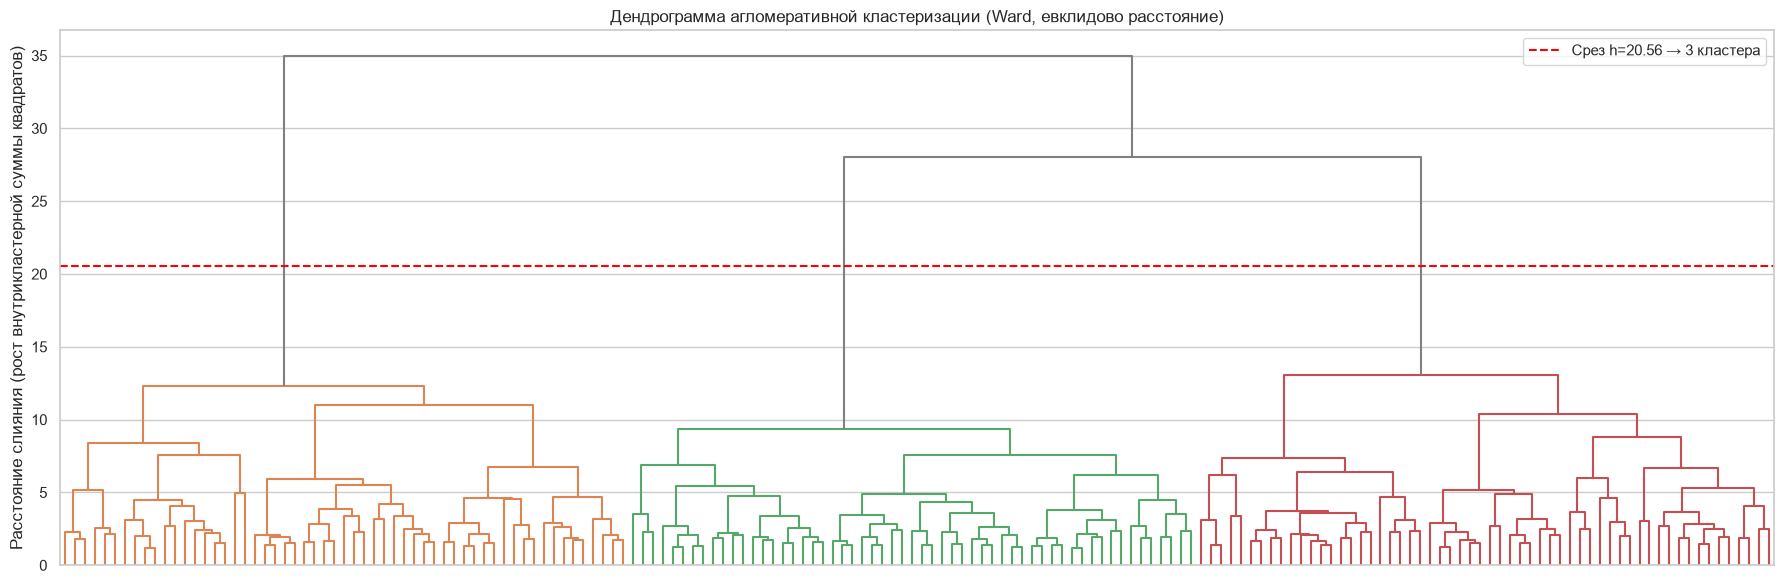

Число кластеров при срезе: 3 | размеры: [57 57 58]


In [14]:
Z_ward = linkage(X_scaled, method="ward", metric="euclidean")
merge_h = Z_ward[::-1, 2]
gaps = pd.DataFrame({"k": range(1, 11), "Высота слияния, ведущего к k кластерам": merge_h[:10]})
gaps["Разница с высотой слияния к k+1"] = gaps["Высота слияния, ведущего к k кластерам"].diff(-1)
display(gaps.round(3).T)

cut_h = (Z_ward[-3, 2] + Z_ward[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(18, 6))
dendrogram(Z_ward, color_threshold=cut_h, above_threshold_color="grey", no_labels=True, ax=ax)
ax.axhline(cut_h, color="red", ls="--", label=f"Срез h={cut_h:.2f} → 3 кластера")
ax.set_title("Дендрограмма агломеративной кластеризации (Ward, евклидово расстояние)")
ax.set_ylabel("Расстояние слияния (рост внутрикластерной суммы квадратов)")
ax.legend()
plt.tight_layout()
savefig("dendrogram_ward")
plt.show()

fcluster_labels = fcluster(Z_ward, t=cut_h, criterion="distance")
print("Число кластеров при срезе:", len(np.unique(fcluster_labels)), "| размеры:", np.bincount(fcluster_labels)[1:])

Самые высокие слияния — 34.97 (последнее, переход 2 → 1 кластер) и 28.05 (переход 3 → 2). Следующее слияние (4 → 3) происходит уже на высоте 13.08. **Наибольший разрыв высот (28.05 − 13.08 = 14.97) приходится между 2 и 3 кластерами** — это самые длинные вертикальные ветви дендрограммы. Горизонтальный срез внутри этого разрыва (h ≈ 20.56, красная линия) пересекает ровно три ветви, поэтому выбирается **3 кластера**. `fcluster` с этим порогом даёт 3 кластера размером 57 / 57 / 58 — те же группы, что и `AgglomerativeClustering(n_clusters=3, linkage="ward")`.

Структура дендрограммы показывает также, что левая группа наиболее обособлена (присоединяется к остальным только последним слиянием на высоте 34.97), а две правые группы объединяются между собой раньше, на высоте 28.05.

,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (справочно)
k,,,,
2,0.2682,64.0008,1.4446,0.4309
3,0.2785,68.9668,1.3946,0.7742
4,0.2395,53.2998,1.6756,0.6582
5,0.2005,45.5160,1.8644,0.6182
6,0.1963,40.3614,1.7525,0.5688
7,0.1898,36.8480,1.7250,0.5255
8,0.1253,34.0376,1.8825,0.3790
9,0.1293,31.8127,1.8641,0.3729
10,0.1374,30.0265,1.7842,0.3700


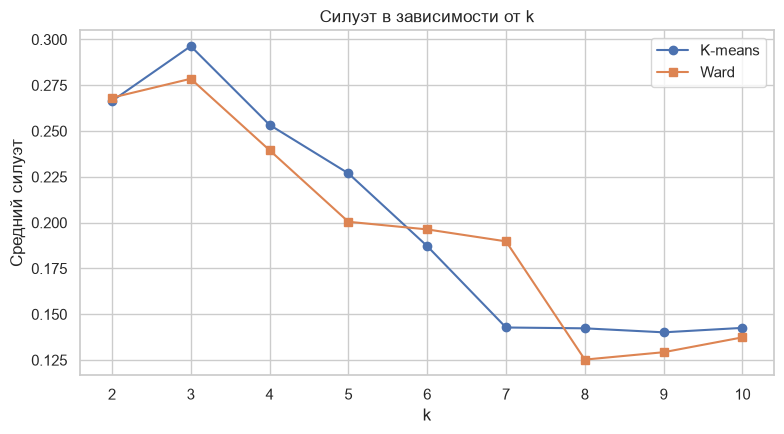

In [15]:
hier_search = []
for k in K_RANGE:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean").fit_predict(X_scaled)
    hier_search.append({"k": k, **internal_metrics(X_scaled, lab), "ARI (справочно)": adjusted_rand_score(y_true, lab)})
hier_search = pd.DataFrame(hier_search).set_index("k")
hier_search.to_csv(RES_DIR / "ward_k_search.csv")
display(hier_search.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kmeans_search.index, kmeans_search["Silhouette"], "o-", label="K-means")
ax.plot(hier_search.index, hier_search["Silhouette"], "s-", label="Ward")
ax.set_xlabel("k")
ax.set_ylabel("Средний силуэт")
ax.set_title("Силуэт в зависимости от k")
ax.legend()
plt.tight_layout()
savefig("silhouette_k_both")
plt.show()

Для Ward силуэт также максимален при **k = 3** (0.279), Calinski–Harabasz максимален (68.97), Davies–Bouldin минимален (1.395). Кривые силуэта K-means и Ward почти совпадают: оба метода видят одну и ту же структуру, K-means при каждом k немного лучше по силуэту, так как напрямую оптимизирует инерцию.

**Итог: K_OPT = 3 для обоих методов.**

## 6. Кластеризация и оценка качества

### 6.1. Обучение итоговых моделей
- `KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)` — k-means++ выбирает начальные центры далеко друг от друга, `n_init=10` запускает алгоритм 10 раз с разной инициализацией и оставляет решение с наименьшей инерцией, `random_state` обеспечивает воспроизводимость.
- `AgglomerativeClustering(n_clusters=3, linkage="ward", metric="euclidean")` — метод Ward допускает только евклидову метрику.

Метки извлекаются `fit_predict` (одномерный массив длины 172).

In [16]:
K_OPT = 3

kmeans = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=SEED)
labels_km = kmeans.fit_predict(X_scaled)

ward = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward", metric="euclidean")
labels_ward = ward.fit_predict(X_scaled)

print("labels_km:", labels_km.shape, "| labels_ward:", labels_ward.shape)
print("Фактическое число кластеров: K-means =", n_clusters_of(labels_km), "| Ward =", n_clusters_of(labels_ward))
print("Инерция K-means:", round(kmeans.inertia_, 3), "| итераций:", kmeans.n_iter_)
sizes = pd.DataFrame({"K-means": pd.Series(labels_km).value_counts().sort_index(), "Ward": pd.Series(labels_ward).value_counts().sort_index()})
sizes.index.name = "Кластер"
display(sizes.T)
print("ARI(K-means, Ward) =", round(adjusted_rand_score(labels_km, labels_ward), 4))
display(pd.crosstab(pd.Series(labels_km, name="K-means"), pd.Series(labels_ward, name="Ward")))

labels_km: (172,) | labels_ward: (172,)
Фактическое число кластеров: K-means = 3 | Ward = 3
Инерция K-means: 1182.463 | итераций: 10


Кластер,0,1,2
K-means,62,50,60
Ward,58,57,57


ARI(K-means, Ward) = 0.8165


Ward,0,1,2
K-means,,,
0,55,6,1
1,0,50,0
2,3,1,56


- Оба метода получили по 3 кластера без вырожденных групп: K-means — 62 / 50 / 60, Ward — 58 / 57 / 57.
- K-means сошёлся за 10 итераций, инерция 1182.46.
- Согласованность методов между собой ARI = 0.817: 161 из 172 объектов (93.6 %) отнесены в соответствующие кластеры одинаково, расхождения касаются 11 объектов, в основном переходных между кластерами 0 и 1 (6 объектов) и 0 и 2.

### 6.2. Внутренние и внешние метрики

In [17]:
results = {}
for name, lab in [("K-means", labels_km), ("Ward", labels_ward)]:
    results[name] = {
        "Кластеров": n_clusters_of(lab),
        **internal_metrics(X_scaled, lab),
        "Dunn": dunn_index(X_scaled, lab),
        "SSE": compactness_table(X_scaled, lab)["SSE (инерция)"].sum(),
        **external_metrics(y_true, lab),
    }
metrics_df = pd.DataFrame(results)
metrics_df.to_csv(RES_DIR / "metrics_comparison.csv")
display(metrics_df.round(4))

for name, lab in [("K-means", labels_km), ("Ward", labels_ward)]:
    print(f"Матрица сопряжённости «класс — кластер», {name}:")
    display(pd.crosstab(pd.Series(y_true, name="Класс"), pd.Series(lab, name="Кластер")))

,K-means,Ward
Кластеров,3.0000,3.0000
Silhouette,0.2963,0.2785
Calinski-Harabasz,75.2868,68.9668
Davies-Bouldin,1.3280,1.3946
Dunn,0.2304,0.1880
SSE,1182.4629,1231.1590
Rand,0.9693,0.8998
ARI,0.9311,0.7742
Jaccard (пары),0.9122,0.7381
Fowlkes-Mallows,0.9541,0.8494


Матрица сопряжённости «класс — кластер», K-means:


Кластер,0,1,2
Класс,,,
1,0,0,59
2,62,3,1
3,0,47,0


Матрица сопряжённости «класс — кластер», Ward:


Кластер,0,1,2
Класс,,,
1,3,0,56
2,55,10,1
3,0,47,0


**Внутренние метрики** (используют только `X_scaled` и метки кластеров):
- *Silhouette* — для объекта $s = \frac{b - a}{\max(a, b)}$, где a — среднее расстояние до объектов своего кластера, b — до объектов ближайшего чужого. K-means 0.296 > Ward 0.279: объекты в среднем ближе к своему кластеру, чем к соседнему, но запас небольшой — кластеры касаются друг друга.
- *Calinski–Harabasz* — отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров и объектов: 75.3 против 69.0, K-means лучше.
- *Davies–Bouldin* — среднее по кластерам максимальное отношение $(S_i + S_j)/d(c_i, c_j)$ (меньше — лучше): 1.328 против 1.395.
- *Dunn* (минимальное межкластерное расстояние / максимальный диаметр): 0.230 против 0.188 — у Ward один из кластеров «шире» (диаметр 10.13).
- *SSE*: 1182.5 против 1231.2 — K-means по построению минимизирует эту величину.

**Внешние метрики** (сравниваются две разметки: истинные сорта `y_true` и метки кластеров):
- *Rand* — доля пар объектов, по которым разметки согласны (обе вместе или обе раздельно): 0.969 и 0.900. *ARI* — Rand с поправкой на случайное совпадение (0 — случайная разметка, 1 — полное совпадение): **0.931** у K-means и **0.774** у Ward.
- *Jaccard* по парам TP / (TP + FP + FN): 0.912 и 0.738; *Fowlkes–Mallows*: 0.954 и 0.849.
- *NMI/AMI* ≈ 0.91 и 0.76; *Homogeneity* (каждый кластер содержит один класс) и *Completeness* (каждый класс в одном кластере) сбалансированы.
- После оптимального сопоставления кластеров классам (Венгерский алгоритм) K-means правильно группирует **97.7 %** объектов (4 ошибки из 172), Ward — 91.9 % (14 ошибок).

Матрицы сопряжённости: у K-means кластер 2 = сорт 1 (59/59), кластер 1 = сорт 3 (47/47) + 3 объекта сорта 2, кластер 0 = сорт 2 (62 из 66). У Ward 10 объектов сорта 2 попали к сорту 3 и 3 объекта сорта 1 — к сорту 2. Таким образом, **основная трудность — сорт 2**, который лежит в центре «подковы» и граничит с обоими другими сортами.

In [18]:
for name, lab in [("K-means", labels_km), ("Ward", labels_ward)]:
    comp = compactness_table(X_scaled, lab)
    center_d, single_d, avg_d = separation_tables(X_scaled, lab)
    comp.to_csv(RES_DIR / f"compactness_{name}.csv")
    print(f"===== {name}: внутрикластерные характеристики (стандартизованное пространство)")
    display(comp.round(3))
    print("Расстояния между центрами кластеров:")
    display(center_d.round(3))
    print("Минимальное расстояние между объектами кластеров (single link):")
    display(single_d.round(3))
    print("Среднее расстояние между объектами кластеров (average link):")
    display(avg_d.round(3))

print("Проверка: центры K-means из cluster_centers_ совпадают со средними по кластерам:",
      np.allclose(kmeans.cluster_centers_, cluster_centers(X_scaled, labels_km)[1], atol=1e-6))

===== K-means: внутрикластерные характеристики (стандартизованное пространство)


,Объектов,Ср. расст. до центра,Макс. расст. до центра,Ср. попарное расст.,Диаметр,SSE (инерция)
Кластер,,,,,,
0,62,2.757,5.589,3.955,8.911,517.426
1,50,2.468,4.013,3.518,6.366,322.653
2,60,2.292,4.805,3.275,7.496,342.384


Расстояния между центрами кластеров:


,0,1,2
0,0.000,4.007,3.768
1,4.007,0.000,5.120
2,3.768,5.120,0.000


Минимальное расстояние между объектами кластеров (single link):


,0,1,2
0,0.000,2.318,2.053
1,2.318,0.000,3.465
2,2.053,3.465,0.000


... (7 outputs left out)

,0,1,2
0,0.000,2.407,1.905
1,2.407,0.000,3.382
2,1.905,3.382,0.000


Среднее расстояние между объектами кластеров (average link):


,0,1,2
0,0.00,5.47,5.09
1,5.47,0.00,6.05
2,5.09,6.05,0.00


Проверка: центры K-means из cluster_centers_ совпадают со средними по кластерам: True


**Компактность** (стандартизованное пространство, 13 измерений): у K-means самый компактный кластер 2 (сорт 1): среднее расстояние до центра 2.29, среднее попарное 3.28, диаметр 7.50. Самый рыхлый — кластер 0 (сорт 2): 2.76, 3.96 и 8.91 соответственно, на него приходится 44 % общей SSE (517.4 из 1182.5). У Ward рыхлыми оказываются два кластера (диаметры 10.13 и 8.27), т. к. переходные объекты распределены иначе.

**Межкластерные расстояния** (K-means):
- между центрами: 0–1 = 4.01, 0–2 = 3.77, 1–2 = **5.12** — кластеры 1 и 2 (сорта 3 и 1) наиболее удалены, кластер 0 (сорт 2) находится между ними;
- минимальное расстояние между объектами (single link): 0–2 = 2.05, 0–1 = 2.32 — меньше среднего внутрикластерного попарного расстояния (3.3–4.0), то есть **границы кластеров соприкасаются**, что объясняет умеренный силуэт;
- среднее расстояние между объектами (average link): 5.2–6.1 — в 1.3–1.9 раза больше внутрикластерного попарного, кластеры разделены.

Расстояния между центрами у K-means (3.77–5.12) больше, чем у Ward (3.70–4.93), а внутрикластерные — в среднем меньше: K-means даёт лучшее соотношение «разделённость / компактность». Для Ward центры вычисляются как среднее объектов кластера (`cluster_centers`), для K-means проверено, что `cluster_centers_` совпадают с такими средними.

## 7. Исследование влияния параметров

### 7.1. K-means: число кластеров, устойчивость и инициализация

In [19]:
k_study = kmeans_search[["Инерция", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "ARI (справочно)"]].copy()
k_study["Мин. размер кластера"] = [np.bincount(kmeans_labels_by_k[k]).min() for k in K_RANGE]
k_study["Макс. размер кластера"] = [np.bincount(kmeans_labels_by_k[k]).max() for k in K_RANGE]
display(k_study.round(4))

stab = []
for k in [2, 3, 4, 5]:
    seeds_labels = [KMeans(n_clusters=k, n_init=1, init="random", random_state=s).fit_predict(X_scaled) for s in range(30)]
    aris = [adjusted_rand_score(a, b) for a, b in combinations(seeds_labels, 2)]
    boot = []
    rng = np.random.default_rng(SEED)
    base = kmeans_labels_by_k[k]
    for _ in range(50):
        idx = rng.choice(len(X_scaled), len(X_scaled), replace=True)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled[idx])
        boot.append(adjusted_rand_score(base, km_b.predict(X_scaled)))
    stab.append({"k": k, "ARI между запусками (n_init=1, random)": np.mean(aris), "ARI бутстрэп (n_init=10)": np.mean(boot), "ARI бутстрэп min": np.min(boot)})
stab = pd.DataFrame(stab).set_index("k")
stab.to_csv(RES_DIR / "kmeans_stability.csv")
display(stab.round(4))

init_study = []
for init in ["k-means++", "random"]:
    for n_init in [1, 10]:
        inertias = [KMeans(n_clusters=K_OPT, init=init, n_init=n_init, random_state=s).fit(X_scaled).inertia_ for s in range(30)]
        init_study.append({"init": init, "n_init": n_init, "Мин. инерция": np.min(inertias), "Средняя инерция": np.mean(inertias), "Макс. инерция": np.max(inertias)})
display(pd.DataFrame(init_study).round(3))

,Инерция,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (справочно),Мин. размер кластера,Макс. размер кластера
k,,,,,,,
2,1575.9560,0.2664,71.1996,1.4731,0.4262,78,94
3,1182.4629,0.2963,75.2868,1.3280,0.9311,50,62
4,1094.4626,0.2534,58.4087,1.7325,0.7654,26,57
5,1036.7731,0.2269,48.2919,1.7221,0.6808,19,55
6,968.3349,0.1872,43.4627,1.8495,0.5581,20,51
7,922.3710,0.1428,39.1651,1.9152,0.4344,18,33
8,883.4078,0.1423,35.8717,1.9441,0.3826,13,29
9,829.9851,0.1401,34.5157,1.8402,0.3865,8,35
10,809.5307,0.1426,31.7177,1.7571,0.3158,13,24


,"ARI между запусками (n_init=1, random)",ARI бутстрэп (n_init=10),ARI бутстрэп min
k,,,
2,0.6116,0.7109,0.2453
3,0.9797,0.9616,0.8777
4,0.7157,0.7853,0.6767
5,0.6174,0.6904,0.4406


,init,n_init,Мин. инерция,Средняя инерция,Макс. инерция
0,k-means++,1,1182.463,1193.931,1509.502
1,k-means++,10,1182.463,1182.463,1182.463
2,random,1,1182.463,1182.843,1183.650
3,random,10,1182.463,1182.463,1182.463


**Влияние k:**
- При k = 2 образуются кластеры 78 и 94 объекта: сорт 2 «разрезается» между двумя крупными группами (ARI = 0.43), силуэт 0.266.
- При **k = 3** все метрики оптимальны, размеры 50–62.
- При k ≥ 4 естественные группы дробятся: при k = 4 минимальный кластер — 26 объектов, при k = 9 — 8; силуэт падает до 0.14, Davies–Bouldin растёт до 1.9, ARI снижается до 0.32–0.39. Инерция продолжает убывать, но это следствие только роста числа центров.

**Устойчивость:**
- Совпадение разбиений при 30 запусках с одной случайной инициализацией (`n_init=1, init="random"`): для k = 3 средний ARI между запусками **0.980**, для k = 2, 4, 5 — лишь 0.61–0.72. Решение при k = 3 практически не зависит от старта.
- Бутстрэп (50 выборок с возвращением, модель предсказывает метки для исходных объектов): для k = 3 средний ARI с базовым разбиением **0.962**, минимум 0.878; для других k — 0.69–0.79 (минимум до 0.25). Три кластера — **устойчивая** структура данных, другие k дают неустойчивые разбиения.

**Влияние инициализации (k = 3, 30 значений random_state):** минимальная инерция 1182.46 достигается при любой стратегии, но с `k-means++` и `n_init=1` в отдельных запусках алгоритм застревает в локальном минимуме (максимальная инерция 1509.5). При `n_init=10` все 30 запусков дают глобальное решение — именно поэтому используется `n_init=10`.

### 7.2. Иерархическая кластеризация: способ связи и метрика расстояния

In [20]:
linkage_study = []
linkage_labels = {}
for link in ["ward", "complete", "average", "single"]:
    for metric in (["euclidean"] if link == "ward" else ["euclidean", "manhattan", "cosine"]):
        lab = AgglomerativeClustering(n_clusters=K_OPT, linkage=link, metric=metric).fit_predict(X_scaled)
        linkage_labels[(link, metric)] = lab
        linkage_study.append({"linkage": link, "metric": metric, "Размеры": sorted(np.bincount(lab).tolist(), reverse=True), **internal_metrics(X_scaled, lab), "ARI": adjusted_rand_score(y_true, lab)})
linkage_study = pd.DataFrame(linkage_study)
linkage_study.to_csv(RES_DIR / "hierarchical_linkage_study.csv", index=False)
display(linkage_study.round(4))

,linkage,metric,Размеры,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI
0,ward,euclidean,"[58, 57, 57]",0.2785,68.9668,1.3946,0.7742
1,complete,euclidean,"[73, 60, 39]",0.2196,52.5555,1.6648,0.5692
2,complete,manhattan,"[61, 57, 54]",0.2859,71.4573,1.3652,0.8509
3,complete,cosine,"[66, 59, 47]",0.2516,62.1119,1.5249,0.7055
4,average,euclidean,"[117, 54, 1]",0.2593,35.7592,1.0805,0.4472
5,average,manhattan,"[121, 50, 1]",0.2586,35.1218,1.0595,0.4757
6,average,cosine,"[64, 56, 52]",0.2844,70.3009,1.3576,0.7721
7,single,euclidean,"[170, 1, 1]",0.1378,2.2922,0.6872,-0.0030
8,single,manhattan,"[170, 1, 1]",0.1378,2.2922,0.6872,-0.0030
9,single,cosine,"[170, 1, 1]",-0.1219,1.1184,1.1321,-0.0030


- **Ward** (евклидова) — сбалансированные кластеры 58 / 57 / 57, силуэт 0.279, ARI 0.774.
- **Complete** (расстояние между кластерами — максимальное расстояние между их объектами): с евклидовой метрикой получаются неравные кластеры 73 / 60 / 39 (ARI 0.57); с **манхэттенской метрикой** результат лучший среди всех вариантов иерархического метода — силуэт 0.286, CH 71.5, ARI 0.851. Манхэттенское расстояние менее чувствительно к большим отклонениям по одному признаку.
- **Average** (среднее расстояние между объектами): с евклидовой и манхэттенской метриками отщепляется одиночный объект (117 / 54 / 1) — два исходных сорта сливаются. Косинусная метрика (сравнивает «профили» признаков, а не их величину) снова даёт сбалансированное разбиение (ARI 0.772).
- **Single** (минимальное расстояние): **цепочечный эффект** — 170 / 1 / 1; группы соединены «мостиками» переходных точек и сливаются в одну. Низкий Davies–Bouldin (0.69) здесь обманчив: метрика «награждает» отделение двух далёких точек; ARI ≈ 0.

Вывод: для данных с соприкасающимися выпуклыми кластерами подходят методы, учитывающие компактность (Ward, complete); single и average с евклидовой метрикой непригодны. Выбор метрики расстояния может менять результат сильнее, чем выбор метода.

### 7.3. DBSCAN: влияние ε и min_samples (дополнительный метод)
DBSCAN применяется в том же стандартизованном 13-мерном пространстве `X_scaled` с евклидовой метрикой, поэтому ε измеряется в единицах стандартных отклонений. Начальный диапазон ε выбирается по k-distance графику (расстояние до k-го соседа, k = min_samples = 2·d = 26).

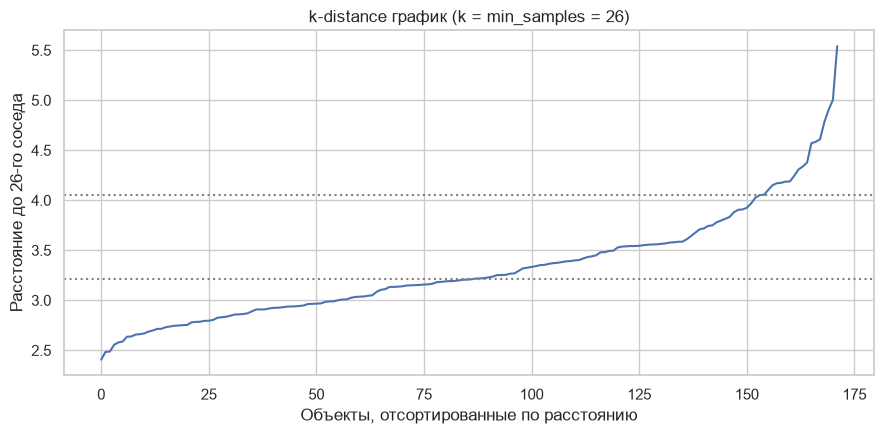

Квантили k-distance: 10% / 50% / 90%: [2.745 3.208 4.054]


In [21]:
MIN_SAMPLES_DEFAULT = 2 * len(FEATURES)
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES_DEFAULT).fit(X_scaled)
kdist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(kdist)
for q in [0.5, 0.9]:
    ax.axhline(np.quantile(kdist, q), ls=":", color="grey")
ax.set_title(f"k-distance график (k = min_samples = {MIN_SAMPLES_DEFAULT})")
ax.set_xlabel("Объекты, отсортированные по расстоянию")
ax.set_ylabel(f"Расстояние до {MIN_SAMPLES_DEFAULT}-го соседа")
plt.tight_layout()
savefig("dbscan_kdistance")
plt.show()
print("Квантили k-distance: 10% / 50% / 90%:", np.quantile(kdist, [0.1, 0.5, 0.9]).round(3))

Для ~88 % объектов k-distance плавно растёт от 2.4 до 4.0 (медиана 3.21, 10 %- и 90 %-квантили — 2.75 и 4.05), и лишь у последних ~20 объектов происходит резкий рост до 5.5 («колено» около ε ≈ 4.0). Классическое правило выбора ε по колену отделяет только редкие удалённые точки, а все остальные объекты при таком ε оказываются в одной связной плотной области: **плотность внутри кластеров и в «мостиках» между ними почти одинакова** — неблагоприятный признак для DBSCAN. Поэтому выполнен перебор ε ∈ [1.6; 4.0] с шагом 0.2 и min_samples ∈ {3, 5, 8, 13, 20, 26}.

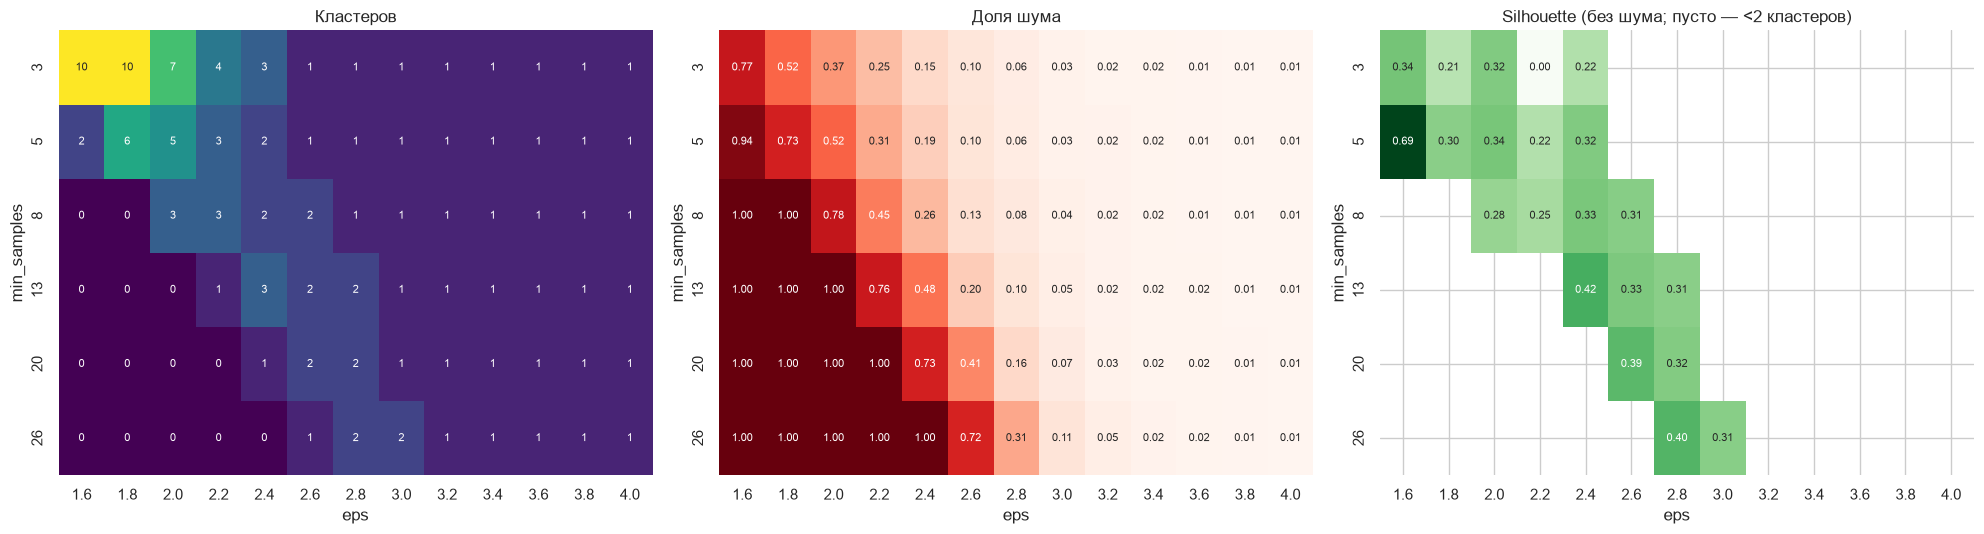

,eps,min_samples,Кластеров,Доля шума,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI (без шума),ARI (шум = отд. класс),Комментарий
26,2.4,8,2,0.2616,0.3330,63.9952,1.1565,0.5038,0.3391,NaN
33,2.6,13,2,0.1977,0.3298,69.0018,1.1597,0.5030,0.3881,NaN
25,2.4,5,2,0.1919,0.3208,67.7898,1.2099,0.5247,0.4075,NaN
40,2.8,20,2,0.1570,0.3172,71.8258,1.2045,0.4954,0.4048,NaN
32,2.6,8,2,0.1337,0.3101,70.5540,1.2427,0.5126,0.4355,NaN
47,3.0,26,2,0.1105,0.3076,72.0408,1.2428,0.4977,0.4318,NaN
39,2.8,13,2,0.1047,0.3051,71.5422,1.2495,0.5096,0.4463,NaN
24,2.4,3,3,0.1512,0.2230,37.0713,1.1596,0.5101,0.4136,NaN
18,2.2,3,4,0.2500,0.0026,25.5387,2.1254,0.4371,0.3301,NaN


Комбинаций без определённых метрик (0 или 1 кластер): 57 из 78


In [22]:
EPS_GRID = np.round(np.arange(1.6, 4.01, 0.2), 2)
MIN_SAMPLES_GRID = [3, 5, 8, 13, 20, 26]
dbscan_rows = []
for eps in EPS_GRID:
    for ms in MIN_SAMPLES_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms, metric="euclidean").fit_predict(X_scaled)
        k = n_clusters_of(lab)
        row = {"eps": eps, "min_samples": ms, "Кластеров": k, "Доля шума": np.mean(lab == -1)}
        if k >= 2:
            row.update(internal_metrics(X_scaled, lab))
            row["ARI (без шума)"] = adjusted_rand_score(y_true[lab != -1], lab[lab != -1])
            row["ARI (шум = отд. класс)"] = adjusted_rand_score(y_true, lab)
        else:
            row["Комментарий"] = "все объекты — шум" if k == 0 else "один кластер: метрики не определены"
        dbscan_rows.append(row)
dbscan_df = pd.DataFrame(dbscan_rows)
dbscan_df.to_csv(RES_DIR / "dbscan_grid.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, col, cmap, fmt in [(axes[0], "Кластеров", "viridis", ".0f"), (axes[1], "Доля шума", "Reds", ".2f"), (axes[2], "Silhouette", "Greens", ".2f")]:
    piv = dbscan_df.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(piv, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(col + (" (без шума; пусто — <2 кластеров)" if col == "Silhouette" else ""))
plt.tight_layout()
savefig("dbscan_grid")
plt.show()

valid = dbscan_df[(dbscan_df["Кластеров"] >= 2) & (dbscan_df["Доля шума"] <= 0.3)]
display(valid.sort_values("Silhouette", ascending=False).head(10).round(4))
print("Комбинаций без определённых метрик (0 или 1 кластер):", (dbscan_df["Кластеров"] < 2).sum(), "из", len(dbscan_df))

- **Малые ε** (1.6–2.0) при min_samples ≥ 8: окрестности слишком малы, ядровых точек нет — **все объекты объявлены шумом** (доля шума 1.00, 0 кластеров). При min_samples = 3 — до 10 мелких кластеров и 37–77 % шума.
- **Большие ε** (≥ 3.2 при любых min_samples): окрестности перекрывают «мостики» между группами, и **все данные сливаются в один кластер**.
- Из 78 комбинаций в **57** получено 0 или 1 кластер — для них внутренние метрики (силуэт, CH, DB) **не определены** и не рассчитываются (`internal_metrics` возвращает NaN, в таблице стоит комментарий).
- Рост min_samples при фиксированном ε увеличивает долю шума (требуется больше соседей для ядровой точки), рост ε при фиксированном min_samples — уменьшает её и уменьшает число кластеров.
- Узкая «рабочая» полоса (ε ≈ 2.2–3.0, причём оптимальный ε растёт с min_samples) даёт **2 кластера**: сорта 1 и 3; сорт 2 при этом почти целиком становится шумом или сливается с сортом 1. Комбинация ε = 1.6, min_samples = 5 даёт силуэт 0.69, но при 94 % шума — это не кластеризация данных, а выделение двух маленьких плотных ядер, поэтому варианты с долей шума > 30 % отбрасываются.

In [23]:
best_db = valid.sort_values("Silhouette", ascending=False).iloc[0]
dbscan = DBSCAN(eps=float(best_db["eps"]), min_samples=int(best_db["min_samples"]), metric="euclidean")
labels_db = dbscan.fit_predict(X_scaled)
noise_mask = labels_db == -1
print(f"DBSCAN eps={dbscan.eps}, min_samples={dbscan.min_samples}: кластеров {n_clusters_of(labels_db)}, шум {noise_mask.sum()} объектов ({noise_mask.mean():.1%})")
print("Ядровых объектов:", len(dbscan.core_sample_indices_))
display(pd.crosstab(pd.Series(y_true, name="Класс"), pd.Series(labels_db, name="DBSCAN")))

DBSCAN eps=2.4, min_samples=8: кластеров 2, шум 45 объектов (26.2%)
Ядровых объектов: 69


DBSCAN,-1,0,1
Класс,,,
1,7,52,0
2,26,39,1
3,12,0,35


Лучший вариант по силуэту при доле шума ≤ 30 %: **ε = 2.4, min_samples = 8** — 2 кластера (91 и 36 объектов), шум 45 объектов (**26.2 %**), ядровых объектов 69. Шумом признаны прежде всего объекты сорта 2 (26 из 66) — разреженной центральной группы. ARI по нешумовым объектам 0.50. Таким образом, плотностной метод на этих данных **не восстанавливает третью группу** и отбрасывает четверть выборки — это подтверждает выбор K-means и Ward в качестве основных методов.

## 8. Визуализация результатов

Кластеризация выполнялась **в полном 13-мерном стандартизованном пространстве**; PCA (2 компоненты, 58.0 % дисперсии) используется **только для визуализации** уже полученных меток. Центры K-means (`cluster_centers_`) и Ward (средние по кластерам) проецируются той же моделью PCA и показаны звёздочками; шум DBSCAN — серыми крестиками.

PCA (только для визуализации): доля дисперсии PC1+PC2 = 0.5803


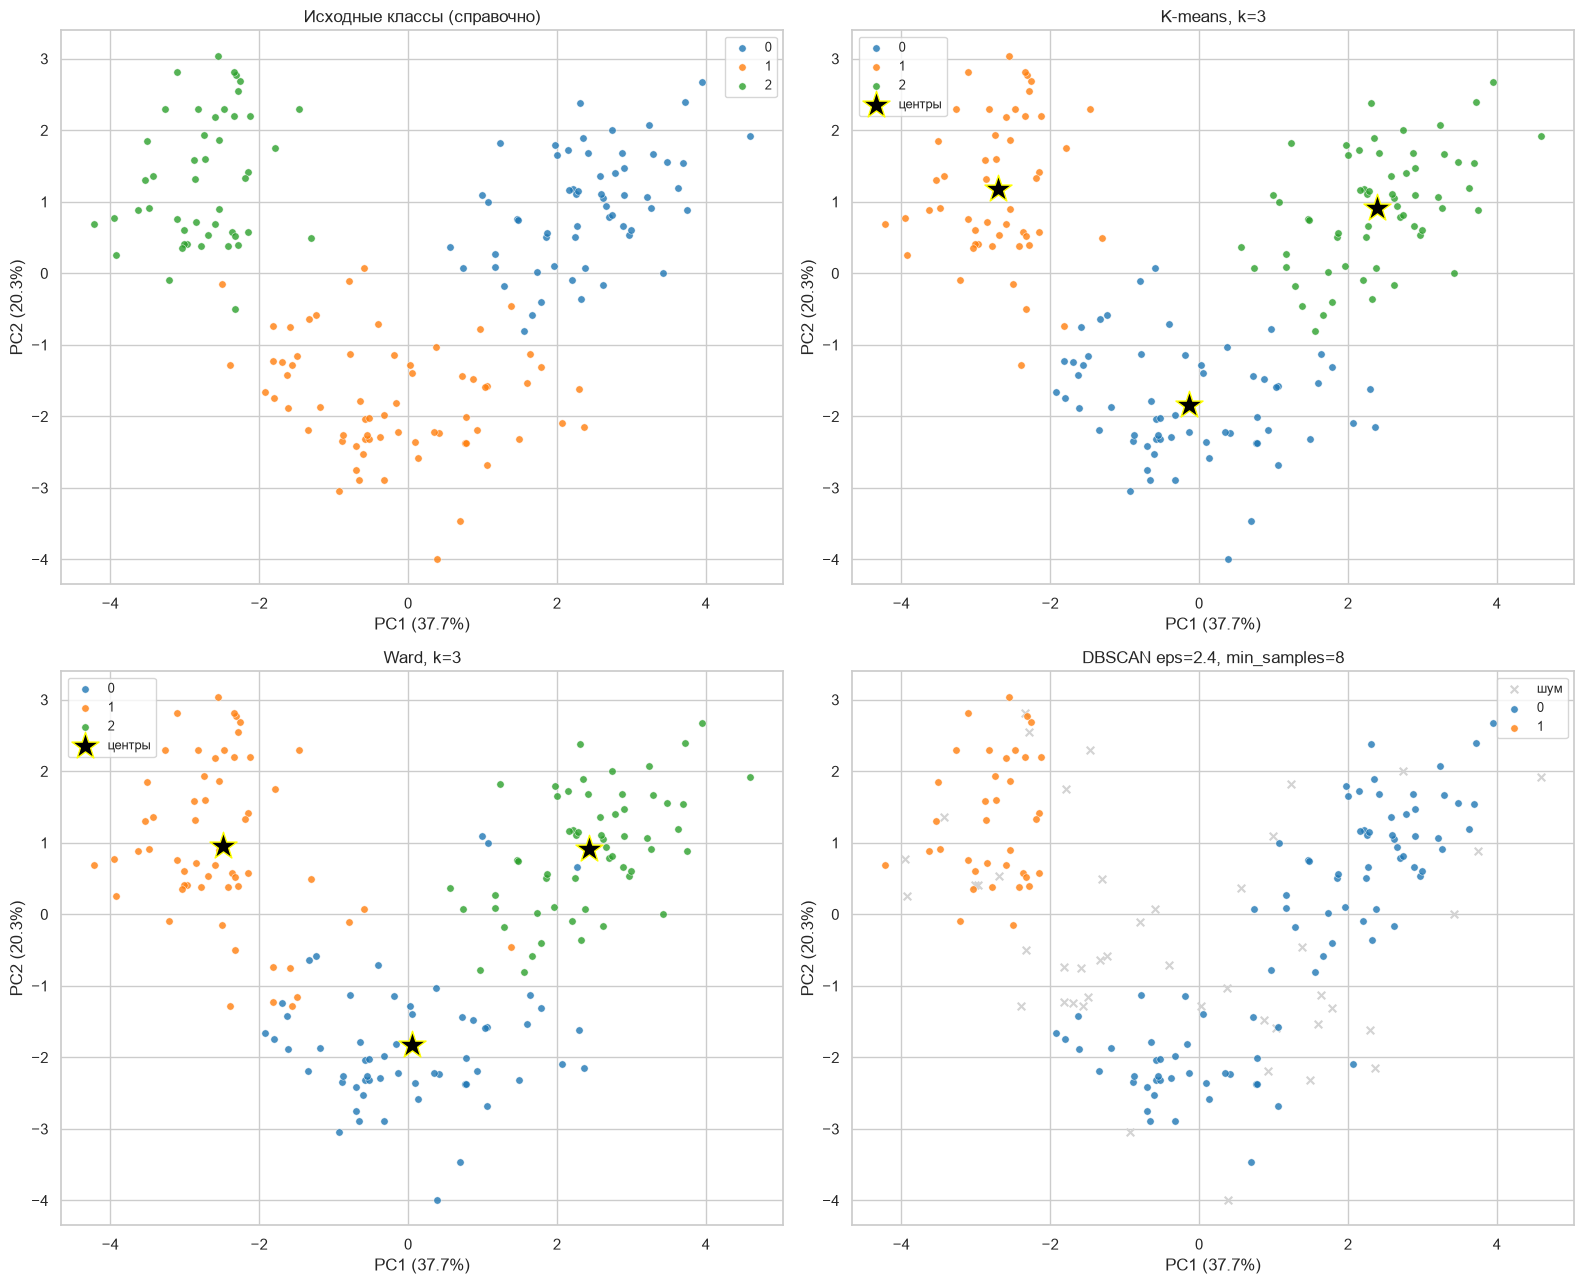

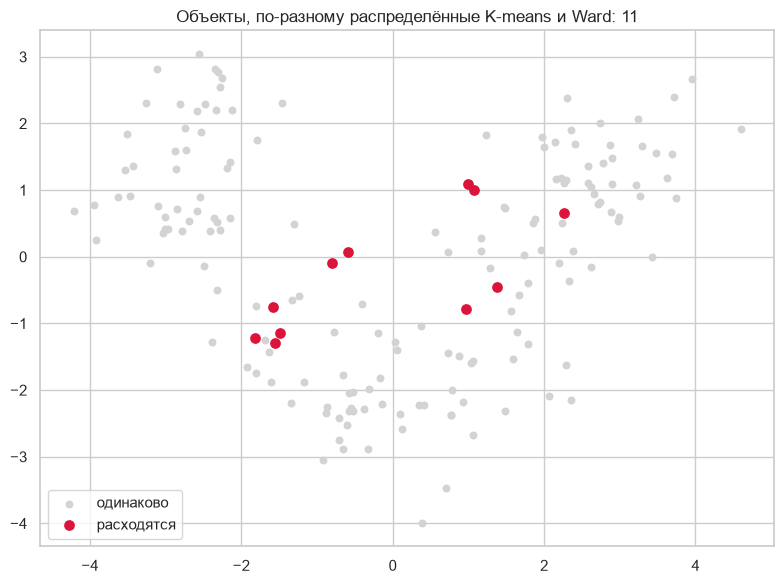

In [24]:
pca2 = PCA(n_components=2, random_state=SEED).fit(X_scaled)
P = pca2.transform(X_scaled)
print("PCA (только для визуализации): доля дисперсии PC1+PC2 =", round(pca2.explained_variance_ratio_.sum(), 4))

km_centers_2d = pca2.transform(kmeans.cluster_centers_)
ward_centers_2d = pca2.transform(cluster_centers(X_scaled, labels_ward)[1])

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
panels = [
    (axes[0, 0], y_true - 1, "Исходные классы (справочно)", None),
    (axes[0, 1], labels_km, "K-means, k=3", km_centers_2d),
    (axes[1, 0], labels_ward, "Ward, k=3", ward_centers_2d),
    (axes[1, 1], labels_db, f"DBSCAN eps={dbscan.eps}, min_samples={dbscan.min_samples}", None),
]
for ax, lab, title, centers in panels:
    for c in sorted(set(lab)):
        m = lab == c
        if c == -1:
            ax.scatter(P[m, 0], P[m, 1], c="lightgrey", marker="x", s=30, label="шум")
        else:
            ax.scatter(P[m, 0], P[m, 1], color=plt.cm.tab10(c), s=28, alpha=0.8, edgecolor="white", linewidth=0.4, label=f"{c}")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="*", s=420, c="black", edgecolor="yellow", label="центры")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
    ax.legend(fontsize=9)
plt.tight_layout()
savefig("clusters_pca")
plt.show()

diff = labels_km != pd.Series(labels_ward).map(pd.crosstab(labels_ward, labels_km).idxmax(axis=1)).to_numpy()
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(P[~diff, 0], P[~diff, 1], c="lightgrey", s=22, label="одинаково")
ax.scatter(P[diff, 0], P[diff, 1], c="crimson", s=45, label="расходятся")
ax.set_title(f"Объекты, по-разному распределённые K-means и Ward: {diff.sum()}")
ax.legend()
plt.tight_layout()
savefig("kmeans_vs_ward_diff")
plt.show()

- Разбиение K-means практически повторяет исходные сорта: три группы вдоль «подковы» с центрами в середине каждой.
- Ward выделяет те же три группы, но граница между нижним и правым кластерами смещена: часть переходных объектов (в центре проекции) Ward относит к другому кластеру. Всего методы расходятся на **11 объектах** (красные точки), все они находятся на границах кластеров — в области «мостиков».
- DBSCAN выделяет только две крайние, наиболее плотные группы; центральная группа и все переходные объекты — шум.
- Ни один метод не ошибается в ядрах групп — различия касаются только пограничных объектов, т. е. **три группы устойчивы** относительно выбора метода.

## 9. Интерпретация кластеров

Центры K-means переводятся в исходные единицы обратным преобразованием `scaler.inverse_transform`; для Ward вычисляются средние значения признаков по кластеру в исходных единицах.

Центры K-means в исходных единицах (scaler.inverse_transform):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
Кластер K-means,,,,,,,,,,,,,
0,12.26,1.89,2.25,20.21,90.87,2.24,2.06,0.36,1.56,2.97,1.06,2.81,502.11
1,13.11,3.34,2.41,21.17,98.68,1.66,0.81,0.45,1.11,7.12,0.69,1.69,618.24
2,13.72,1.99,2.45,17.00,106.83,2.82,2.96,0.29,1.91,5.49,1.06,3.14,1109.62


Средние по кластерам Ward в исходных единицах:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
Кластер Ward,,,,,,,,,,,,,
0,12.32,1.89,2.27,20.44,90.43,2.31,2.17,0.36,1.62,3.01,1.07,2.90,498.76
1,13.01,3.17,2.40,20.84,100.18,1.69,0.87,0.45,1.13,6.61,0.73,1.75,625.74
2,13.74,1.99,2.43,16.81,105.67,2.84,2.99,0.29,1.91,5.59,1.06,3.14,1123.25


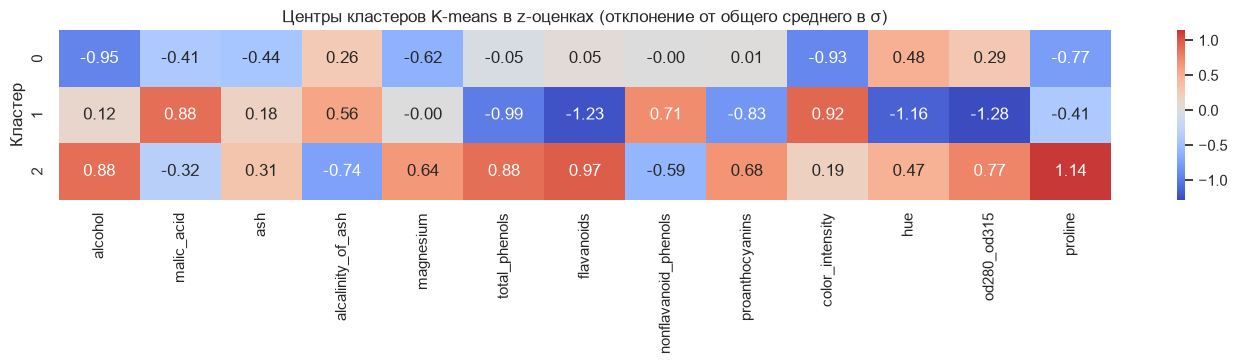

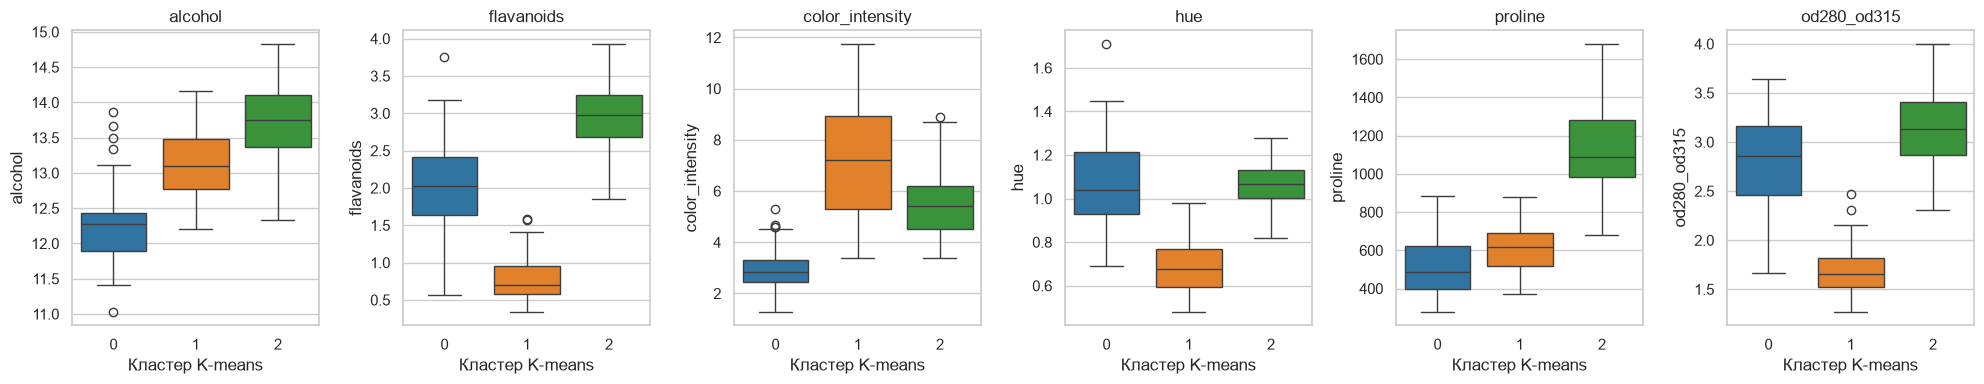

In [25]:
centers_orig = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=FEATURES)
centers_orig.index.name = "Кластер K-means"
print("Центры K-means в исходных единицах (scaler.inverse_transform):")
display(centers_orig.round(2))

profile_km = X.assign(cluster=labels_km).groupby("cluster")[FEATURES].mean()
profile_ward = X.assign(cluster=labels_ward).groupby("cluster")[FEATURES].mean()
profile_km.index.name = "Кластер K-means"
profile_ward.index.name = "Кластер Ward"
print("Средние по кластерам Ward в исходных единицах:")
display(profile_ward.round(2))
centers_orig.to_csv(RES_DIR / "kmeans_centers_original_units.csv")

z_profile = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
plt.figure(figsize=(14, 3.8))
sns.heatmap(z_profile, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Центры кластеров K-means в z-оценках (отклонение от общего среднего в σ)")
plt.ylabel("Кластер")
plt.tight_layout()
savefig("cluster_profiles")
plt.show()

key = ["alcohol", "flavanoids", "color_intensity", "hue", "proline", "od280_od315"]
fig, axes = plt.subplots(1, len(key), figsize=(20, 4))
for ax, col in zip(axes, key):
    sns.boxplot(x=labels_km, y=X[col], ax=ax, hue=labels_km, palette="tab10", legend=False)
    ax.set_title(col)
    ax.set_xlabel("Кластер K-means")
plt.tight_layout()
savefig("cluster_boxplots")
plt.show()

Содержательно кластеры описываются признаками с наибольшими отклонениями центров (тепловая карта z-оценок): `proline`, `flavanoids`, `color_intensity`, `hue`, `od280_od315`, `alcohol`.

| Кластер K-means | Объектов | Характеристика (центр в исходных единицах) | Соответствует |
|---|---|---|---|
| **2 — «насыщенные, крепкие, богатые пролином»** | 60 | высокий алкоголь (13.72 %), очень высокий пролин (1110 мг/л, +1.1σ), много флавоноидов (2.96) и фенолов (2.82), высокий OD280/OD315 (3.14), средняя интенсивность цвета (5.49), низкая щёлочность золы (17.0) | сорт 1 (59 из 59) |
| **0 — «лёгкие, светлые»** | 62 | самый низкий алкоголь (12.26 %), низкий пролин (502), **очень низкая интенсивность цвета (2.97, −0.9σ)**, светлый оттенок (`hue` 1.06), средние фенолы и флавоноиды (2.06), меньше магния (90.9) | сорт 2 (62 из 66) |
| **1 — «тёмные, с низким содержанием фенолов»** | 50 | средний алкоголь (13.11 %), **очень мало флавоноидов (0.81, −1.2σ)** и фенолов (1.66), низкий OD280/OD315 (1.69), **высокая интенсивность цвета (7.12)** и низкий `hue` (0.69), много яблочной кислоты (3.34) | сорт 3 (47 из 47) |

Профили кластеров Ward отличаются от K-means не более чем на несколько процентов (например, пролин 1123 / 499 / 626 против 1110 / 502 / 618), то есть содержательная интерпретация не зависит от метода. Наиболее разделяющие признаки: **пролин** отличает кластер 2 от остальных, **флавоноиды/OD280** — кластер 1, **интенсивность цвета** — кластер 0 от кластера 1.

## 10. Сравнение методов

In [26]:
summary = pd.DataFrame({
    "K-means": {**results["K-means"], "Размеры кластеров": sorted(np.bincount(labels_km).tolist(), reverse=True), "Доля шума": 0.0},
    "Ward": {**results["Ward"], "Размеры кластеров": sorted(np.bincount(labels_ward).tolist(), reverse=True), "Доля шума": 0.0},
    "DBSCAN (доп.)": {"Кластеров": n_clusters_of(labels_db), **internal_metrics(X_scaled, labels_db), **external_metrics(y_true, labels_db),
                      "Размеры кластеров": sorted(np.bincount(labels_db[labels_db != -1]).tolist(), reverse=True), "Доля шума": noise_mask.mean()},
})
order = ["Кластеров", "Размеры кластеров", "Доля шума", "Silhouette", "Calinski-Harabasz", "Davies-Bouldin", "Dunn", "SSE",
         "Rand", "ARI", "Jaccard (пары)", "Fowlkes-Mallows", "NMI", "AMI", "Homogeneity", "Completeness", "V-measure", "Accuracy (Венгерский алгоритм)"]
summary = summary.reindex(order)
summary.to_csv(RES_DIR / "summary_all_methods.csv")
display(summary.map(lambda v: round(v, 4) if isinstance(v, float) else v))

,K-means,Ward,DBSCAN (доп.)
Кластеров,3,3,2
Размеры кластеров,"[62, 60, 50]","[58, 57, 57]","[91, 36]"
Доля шума,0.0,0.0,0.2616
Silhouette,0.2963,0.2785,0.333
Calinski-Harabasz,75.2868,68.9668,63.9952
Davies-Bouldin,1.328,1.3946,1.1565
Dunn,0.2304,0.188,NaN
SSE,1182.4629,1231.159,NaN
Rand,0.9693,0.8998,0.7373
ARI,0.9311,0.7742,0.5038


| Критерий | K-means | Ward | DBSCAN |
|---|---|---|---|
| Число кластеров / шум | 3 / 0 % | 3 / 0 % | 2 / 26 % |
| Silhouette ↑ | **0.296** | 0.279 | 0.333* |
| Calinski–Harabasz ↑ | **75.3** | 69.0 | 64.0* |
| Davies–Bouldin ↓ | 1.328 | 1.395 | 1.157* |
| ARI ↑ | **0.931** | 0.774 | 0.504* |
| Jaccard ↑ | **0.912** | 0.738 | 0.559* |
| Устойчивость (ARI бутстрэп) | 0.962 | детерминирован | — |

\* метрики DBSCAN считаются только по 74 % нешумовых объектов и только для двух хорошо отделённых групп, поэтому формально лучшие Silhouette и DB **не означают лучшего разбиения**: сравнение с методами, разбившими все 172 объекта, некорректно.

**Вывод по сравнению:** K-means превосходит Ward по всем внутренним и внешним метрикам. Причина — итеративное уточнение центров: Ward принимает жадные необратимые решения о слиянии, и переходные объекты, попавшие на раннем шаге не в ту ветвь, уже не могут быть переназначены; K-means перераспределяет их к ближайшему центру. При этом методы согласованы (ARI между ними 0.82), их кластеры имеют одинаковую интерпретацию, а расхождения касаются только 11 пограничных объектов.

## 11. Заключение

1. **Данные.** Wine Dataset (178 → 172 объекта после удаления 6 многомерных выбросов, 13 числовых признаков, без пропусков). Признаки имеют разные шкалы, часть распределений скошена или многовершинна; многовершинность и статистика Хопкинса 0.69 указывают на наличие кластерной структуры. Признаки стандартизованы `StandardScaler`.
2. **Число кластеров.** Метод локтя, силуэт, Calinski–Harabasz, Davies–Bouldin и дендрограмма Ward согласованно указывают на **k = 3**; бутстрэп подтверждает, что разбиение на 3 группы устойчиво (ARI 0.96), а на другое число групп — нет.
3. **Эффективность методов.** Лучший результат — **K-means** (силуэт 0.296, CH 75.3, DB 1.33; ARI с сортами 0.931, 97.7 % объектов сгруппированы в соответствии с сортом). **Ward** немного уступает (силуэт 0.279, ARI 0.774) из-за жадного характера объединения, но даёт ту же структуру и наглядную дендрограмму. Абсолютные значения силуэта (≈ 0.3) говорят о том, что кластеры выпуклые и разделимые, но соприкасающиеся.
4. **Интерпретация кластеров.** Выделены три типа вин: крепкие вина с высоким содержанием пролина и флавоноидов; лёгкие светлые вина с низким алкоголем и низкой интенсивностью цвета; тёмные вина с низким содержанием фенольных соединений и высокой яблочной кислотой. Они практически совпадают с тремя сортами винограда, хотя метки сортов в кластеризации не использовались.
5. **Влияние параметров.** Для K-means критичны k (неверное k снижает ARI с 0.93 до 0.3–0.4) и число инициализаций (`n_init=1` иногда даёт локальный минимум). Для иерархического метода решающее значение имеет способ связи: single и average с евклидовой метрикой дают вырожденные разбиения (цепочечный эффект), а complete с манхэттенской метрикой даже лучше Ward. DBSCAN крайне чувствителен к ε: узкая область параметров даёт 2 кластера, вне её — либо весь шум, либо один кластер.
6. **Применимость.** Для данных с компактными выпуклыми кластерами близкой плотности и размера, соединёнными переходными объектами, наиболее подходят методы, минимизирующие внутрикластерный разброс (K-means, Ward). Плотностные методы (DBSCAN) на таких данных малоэффективны, особенно в пространстве высокой размерности.

## 12. Список источников

1. Wine Data Set. UCI Machine Learning Repository. — URL: https://archive.ics.uci.edu/dataset/109/wine
2. Forina M. et al. PARVUS — An Extendible Package for Data Exploration, Classification and Correlation. Institute of Pharmaceutical and Food Analysis and Technologies, Genoa, 1988.
3. Документация scikit-learn: Clustering. — URL: https://scikit-learn.org/stable/modules/clustering.html
4. Документация scikit-learn: Clustering performance evaluation. — URL: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
5. Документация SciPy: Hierarchical clustering (`scipy.cluster.hierarchy`). — URL: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html
6. Kaufman L., Rousseeuw P. J. Finding Groups in Data: An Introduction to Cluster Analysis. — Wiley, 1990.
7. Ester M., Kriegel H.-P., Sander J., Xu X. A density-based algorithm for discovering clusters in large spatial databases with noise // KDD-96. — 1996. — P. 226–231.
8. Hubert L., Arabie P. Comparing partitions // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
9. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning. — 2nd ed. — Springer, 2009. — Ch. 14.3.

## Приложение

Полный листинг программного кода приведён в ячейках кода данного ноутбука. Результаты расчётов сохранены в `results/*.csv`, рисунки — в `figures/*.png`. Версии библиотек — в `requirements.txt`.